# Phase 1 Complete Analysis — UCI Student Performance — Math (`student_performance`)

**Source:** [UCI Machine Learning Repository (ID 320)](https://archive.ics.uci.edu/dataset/320/student+performance) / [Direct CSV](https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/04_Apply/Students_Alcohol_Consumption/student-mat.csv)  
**Domain & Goal:** Secondary school mathematics achievement dataset (`395` rows × `33` columns, `;`-delimited; target: final grade `G3` [`0–20`]). Key challenges include quoted integer strings in `G1`/`G2`, zero-inflated final grades (`G3 = 0` dropouts), and strong longitudinal collinearity (`G1`, `G2` -> `G3`).

---
## 1. Dataset Overview & Semantic Column Profiling
**What we did & why:** We loaded the raw CSV using string-first two-pass ingestion (`ads.ingestion.load_csv`) so pandas never silently coerces formatting quirks, verified the raw file SHA-256 checksum, and classified every column into one of 10 semantic types (`numeric_continuous`, `numeric_discrete`, `binary`, `categorical_nominal`, `categorical_ordinal`, `datetime`, `id_like`, `free_text`, `constant`, `unknown`).

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

DATASET = "student_performance"
OUT_DIR = Path("..") / "outputs" / DATASET
CLEAN_CSV = Path("..") / "data" / "cleaned" / f"{DATASET}_cleaned.csv"
IMPUTED_CSV = Path("..") / "data" / "cleaned" / f"{DATASET}_cleaned_imputed.csv"

prof = json.loads((OUT_DIR / "profile.json").read_text(encoding="utf-8"))
print(f"Dataset: {prof['dataset_name']} | Raw shape: {prof['n_rows']:,} rows x {prof['n_cols']} cols | Exact duplicates: {prof['n_duplicate_rows']}")
prof_df = pd.DataFrame(prof["columns"])[["name", "raw_dtype", "semantic_type", "pct_missing", "n_unique", "semantic_type_reason"]]
display(prof_df)

Dataset: student_performance | Raw shape: 395 rows x 33 cols | Exact duplicates: 0


name,raw_dtype,semantic_type,pct_missing,n_unique,semantic_type_reason
school,object,binary,0.0%,2,"string column with 2 distinct normalized values ('GP', 'MS')"
sex,object,binary,0.0%,2,"binary string/mixed encoding (gender binary (Male/Female): ['F', 'M'])"
age,int64,numeric_discrete,0.0%,8,integer values with 8 unique levels (unique ratio 2.0%)
address,object,binary,0.0%,2,"string column with 2 distinct normalized values ('U', 'R')"
famsize,object,binary,0.0%,2,"string column with 2 distinct normalized values ('GT3', 'LE3')"
Pstatus,object,binary,0.0%,2,"string column with 2 distinct normalized values ('T', 'A')"
Medu,int64,numeric_discrete,0.0%,5,integer values with 5 unique levels (unique ratio 1.3%)
Fedu,int64,numeric_discrete,0.0%,5,integer values with 5 unique levels (unique ratio 1.3%)
Mjob,object,categorical_nominal,0.0%,5,string categorical with 5 normalized unique values (raw=5)
Fjob,object,categorical_nominal,0.0%,5,string categorical with 5 normalized unique values (raw=5)


## 2. Automated Data Cleaning & Step-by-Step Audit Log
**What we did & why:** We executed the 12-step deterministic cleaning pipeline (`ads.cleaning.clean_dataset`):
1. **Header & Whitespace/Unicode Normalization:** Stripped leading/trailing spaces and invisible characters.
2. **Missing Placeholder Normalization:** Converted placeholder tokens (`'?'`, `'N/A'`, `'null'`, `''`, and configured `'unknown'`) to `NaN`.
3. **Category Standardization & Type Conversion:** Unified case variants, parsed formatted numeric strings, and enforced domain validity ranges.
4. **Duplicate & Structural Drops:** Removed exact duplicate rows and redundant index/empty columns.
5. **Dual Missingness & Outlier Policy:** Saved both the **conservative primary dataset** (`_cleaned.csv`, preserving `NaN` and flagging $1.5\times\text{IQR}$ outliers without deleting valid extremes) and the **imputed secondary dataset** (`_cleaned_imputed.csv` with `__was_missing` indicator flags).

In [2]:
# Display the step-by-step cleaning audit log with before/after cell examples
display(Markdown((OUT_DIR / "cleaning_log.md").read_text(encoding="utf-8")))

# Cleaning Log — `student_performance`

## Summary
2 cleaning step group(s) recorded; 0 column(s) type-converted; 0 cell(s) normalized (whitespace/missing tokens/categories); 0 duplicate row(s) removed; 0 row(s) dropped for structural/missingness rules.

## Step-by-Step Log

| Step | Column | Action | Severity | Cells Affected | Rows (Before -> After) | Reason | Examples (Before -> After) |
| :--- | :--- | :--- | :--- | ---: | ---: | :--- | :--- |
| `standardize_categories` | `guardian` | `flagged_fuzzy_variants` | warning | 0 | 395 -> 395 | Flagged near-duplicate/abbreviation label candidate(s) for human review (not auto-merged): 'other' (32) -> 'mother' (273) [fuzzy, sim=0.91]. | `other` -> `other` |
| `handle_outliers` | `age` | `flagged_outliers` | info | 0 | 395 -> 395 | Flagged 1 outlier(s) (0.3%) and 0 extreme outlier(s) in 'age' (action=flag; values untouched). | `22` -> `22` |
| `handle_outliers` | `Fedu` | `flagged_outliers` | info | 0 | 395 -> 395 | Flagged 2 outlier(s) (0.5%) and 0 extreme outlier(s) in 'Fedu' (action=flag; values untouched). | `0` -> `0`; `0` -> `0` |
| `handle_outliers` | `traveltime` | `flagged_outliers` | info | 0 | 395 -> 395 | Flagged 31 outlier(s) (7.8%) and 0 extreme outlier(s) in 'traveltime' (action=flag; values untouched). | `3` -> `3`; `3` -> `3`; `3` -> `3` |
| `handle_outliers` | `studytime` | `flagged_outliers` | info | 0 | 395 -> 395 | Flagged 27 outlier(s) (6.8%) and 0 extreme outlier(s) in 'studytime' (action=flag; values untouched). | `4` -> `4`; `4` -> `4`; `4` -> `4` |
| `handle_outliers` | `failures` | `flagged_outliers` | info | 0 | 395 -> 395 | Flagged 33 outlier(s) (8.4%) and 0 extreme outlier(s) in 'failures' (action=flag; values untouched). | `3` -> `3`; `3` -> `3`; `2` -> `2` |
| `handle_outliers` | `famrel` | `flagged_outliers` | info | 0 | 395 -> 395 | Flagged 26 outlier(s) (6.6%) and 0 extreme outlier(s) in 'famrel' (action=flag; values untouched). | `1` -> `1`; `2` -> `2`; `2` -> `2` |
| `handle_outliers` | `freetime` | `flagged_outliers` | info | 0 | 395 -> 395 | Flagged 19 outlier(s) (4.8%) and 0 extreme outlier(s) in 'freetime' (action=flag; values untouched). | `1` -> `1`; `1` -> `1`; `1` -> `1` |
| `handle_outliers` | `Dalc` | `flagged_outliers` | info | 0 | 395 -> 395 | Flagged 18 outlier(s) (4.6%) and 0 extreme outlier(s) in 'Dalc' (action=flag; values untouched). | `5` -> `5`; `4` -> `4`; `5` -> `5` |
| `handle_outliers` | `absences` | `flagged_outliers` | info | 0 | 395 -> 395 | Flagged 15 outlier(s) (3.8%) and 5 extreme outlier(s) in 'absences' (action=flag; values untouched). | `25` -> `25`; `54` -> `54`; `26` -> `26` |
| `handle_outliers` | `G2` | `flagged_outliers` | info | 0 | 395 -> 395 | Flagged 13 outlier(s) (3.3%) and 0 extreme outlier(s) in 'G2' (action=flag; values untouched). | `0` -> `0`; `0` -> `0`; `0` -> `0` |


## 3. Cleaned Dataset Preview (Conservative vs. Imputed)
**What we did & why:** Below we inspect the first 5 rows and shapes of both the conservative cleaned dataset (`NaN` preserved for unbiased statistical testing) and the imputed dataset (median/mode imputed with `__was_missing` binary indicators).

In [3]:
df_clean = pd.read_csv(CLEAN_CSV)
df_imputed = pd.read_csv(IMPUTED_CSV)
print(f"Conservative cleaned shape: {df_clean.shape} | Imputed cleaned shape: {df_imputed.shape}")
display(df_clean.head(5))

Conservative cleaned shape: (395, 33) | Imputed cleaned shape: (395, 33)


school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6.0,5,6,6
GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4.0,5,5,6
GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10.0,7,8,10
GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2.0,15,14,15
GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4.0,6,10,10


## 4. Exploratory Data Analysis (EDA) & Visualizations
**What we did & why:** Using `ads.eda.run_eda`, we generated 150-DPI static PNG visualizations covering dataset overview, missingness patterns, univariate numeric histograms + KDEs, IQR boxplots, categorical frequency distributions, target class balance, and bivariate relationships (Pearson $r$ / Spearman $\rho$ correlation heatmaps, bias-corrected Cramér's $V$, and $\eta^2$ group breakdowns). Every chart is paired below with a note explaining what it reveals about the data.

#### 33 columns; the most common type is numeric_discrete (15 columns)
*Figure 1. 33 columns; the most common type is numeric_discrete (15 columns).* Count of columns by the semantic type the pipeline inferred (after cleaning).


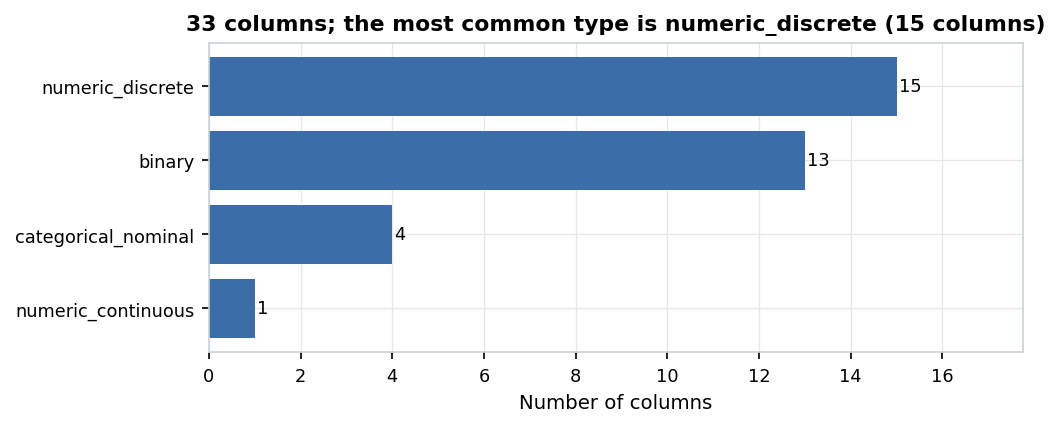

#### Numeric distributions (1/3): most skewed here is 'failures' (skew +2.39)
*Figure 2. Numeric distributions (1/3): most skewed here is 'failures' (skew +2.39).* Histogram (with a smooth density curve for many-valued columns) and a box plot per column. Orange line = mean, green dashed line = median; red dots are values beyond 1.5×IQR.


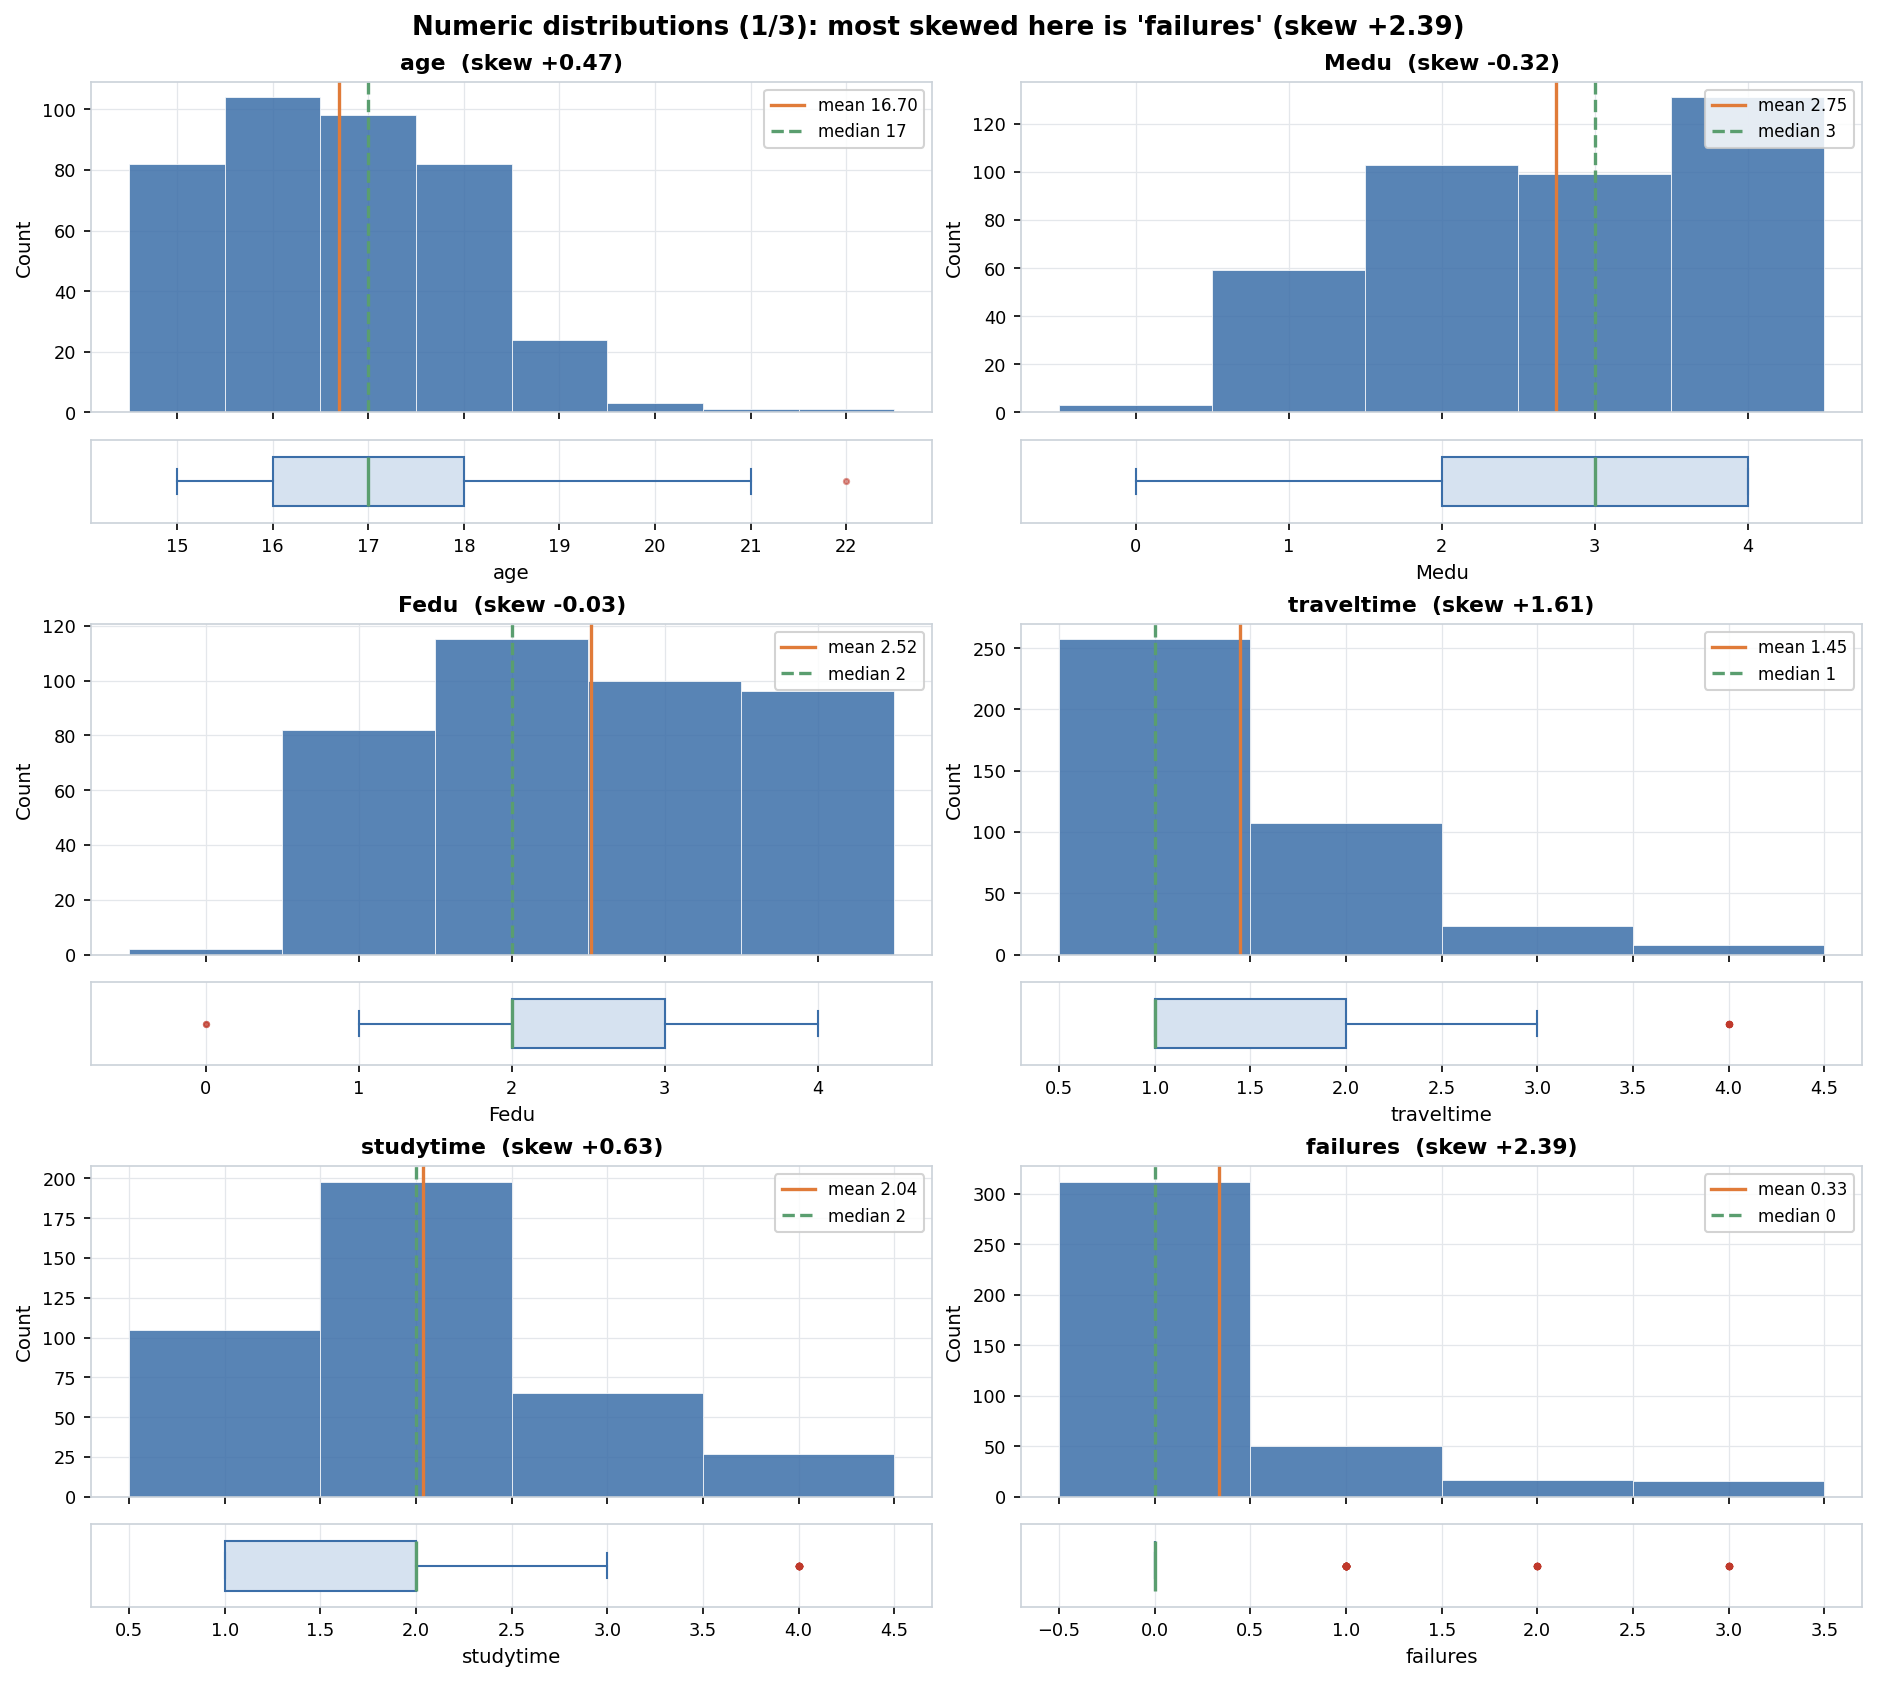

#### Numeric distributions (2/3): most skewed here is 'Dalc' (skew +2.19)
*Figure 3. Numeric distributions (2/3): most skewed here is 'Dalc' (skew +2.19).* Histogram (with a smooth density curve for many-valued columns) and a box plot per column. Orange line = mean, green dashed line = median; red dots are values beyond 1.5×IQR.


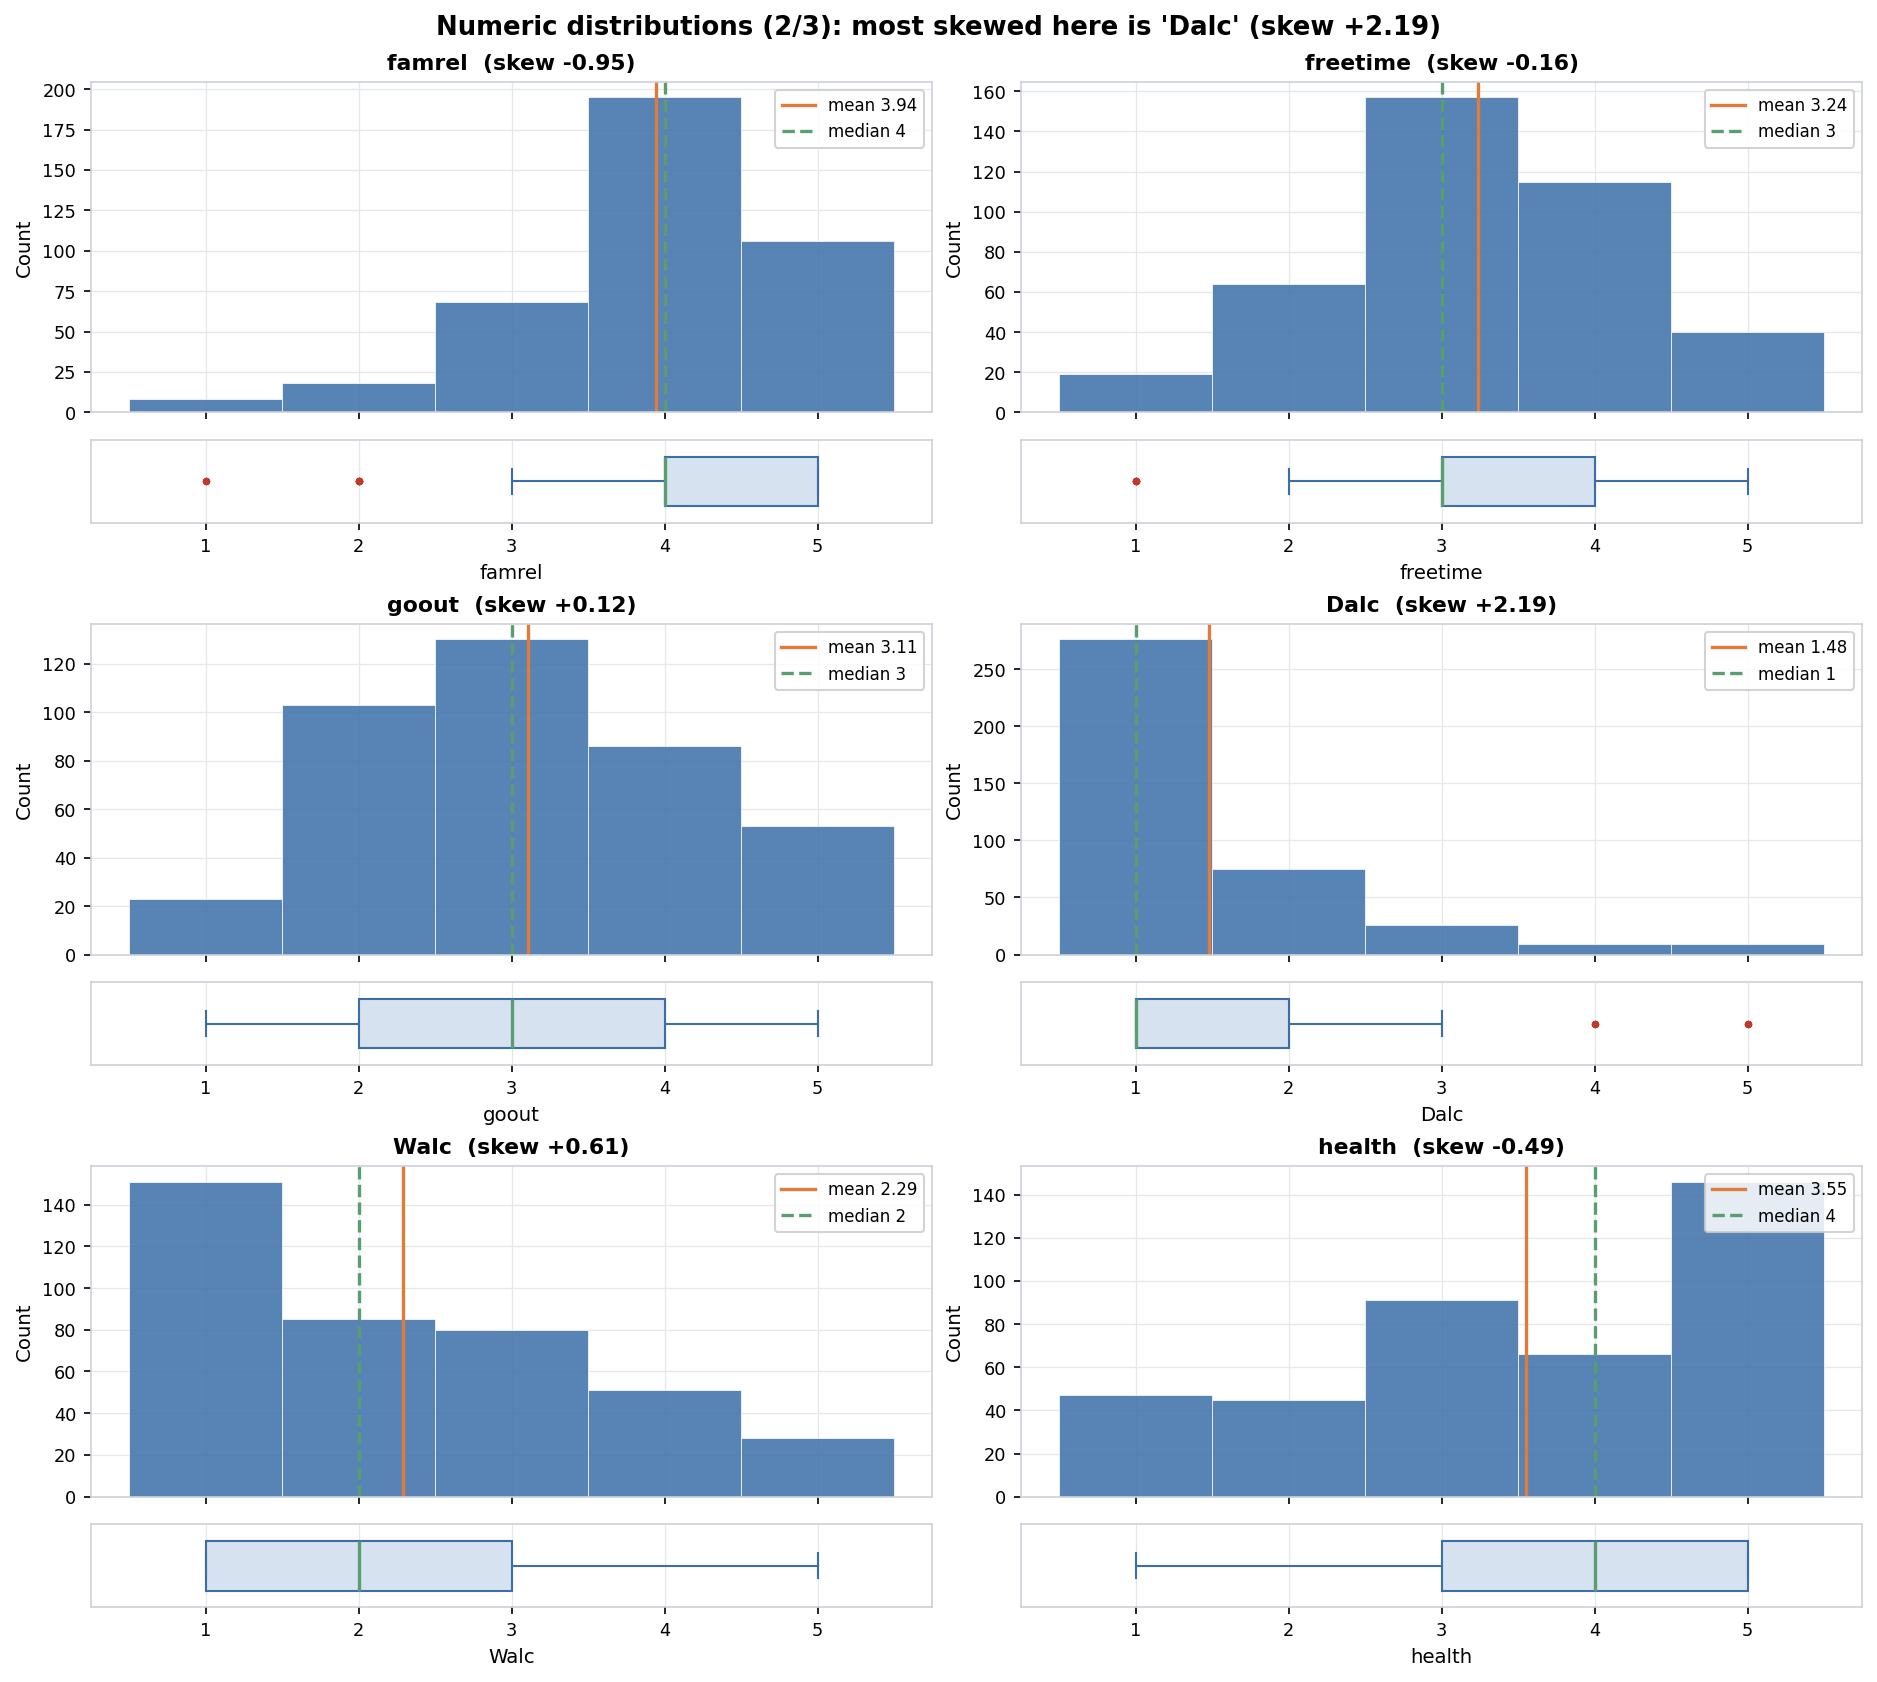

#### Numeric distributions (3/3): most skewed here is 'absences' (skew +3.67)
*Figure 4. Numeric distributions (3/3): most skewed here is 'absences' (skew +3.67).* Histogram (with a smooth density curve for many-valued columns) and a box plot per column. Orange line = mean, green dashed line = median; red dots are values beyond 1.5×IQR.


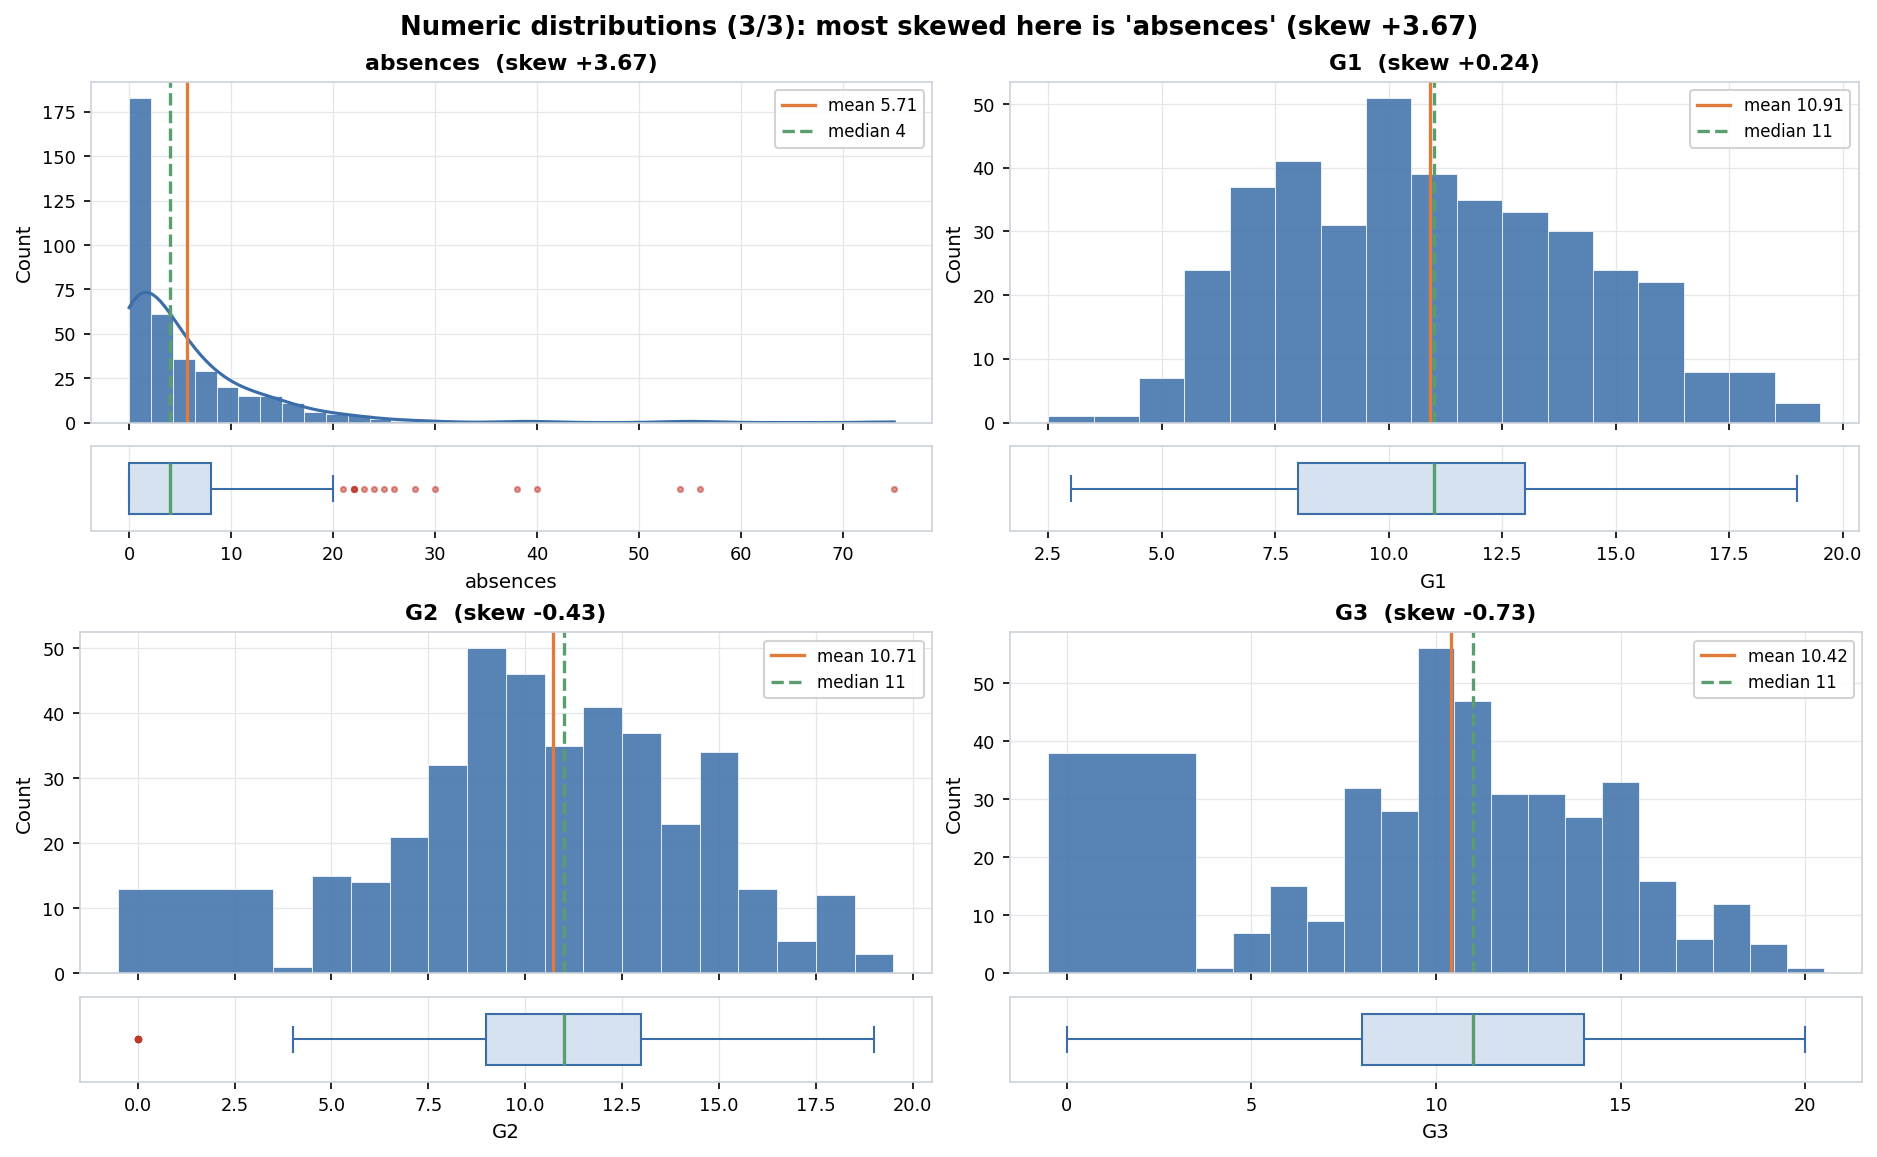

#### 'absences' is right-skewed (skew +3.67)
*Figure 5. 'absences' is right-skewed (skew +3.67).* Close-up of a skewed or outlier-heavy column. The right panel shows the same values on a log1p scale.


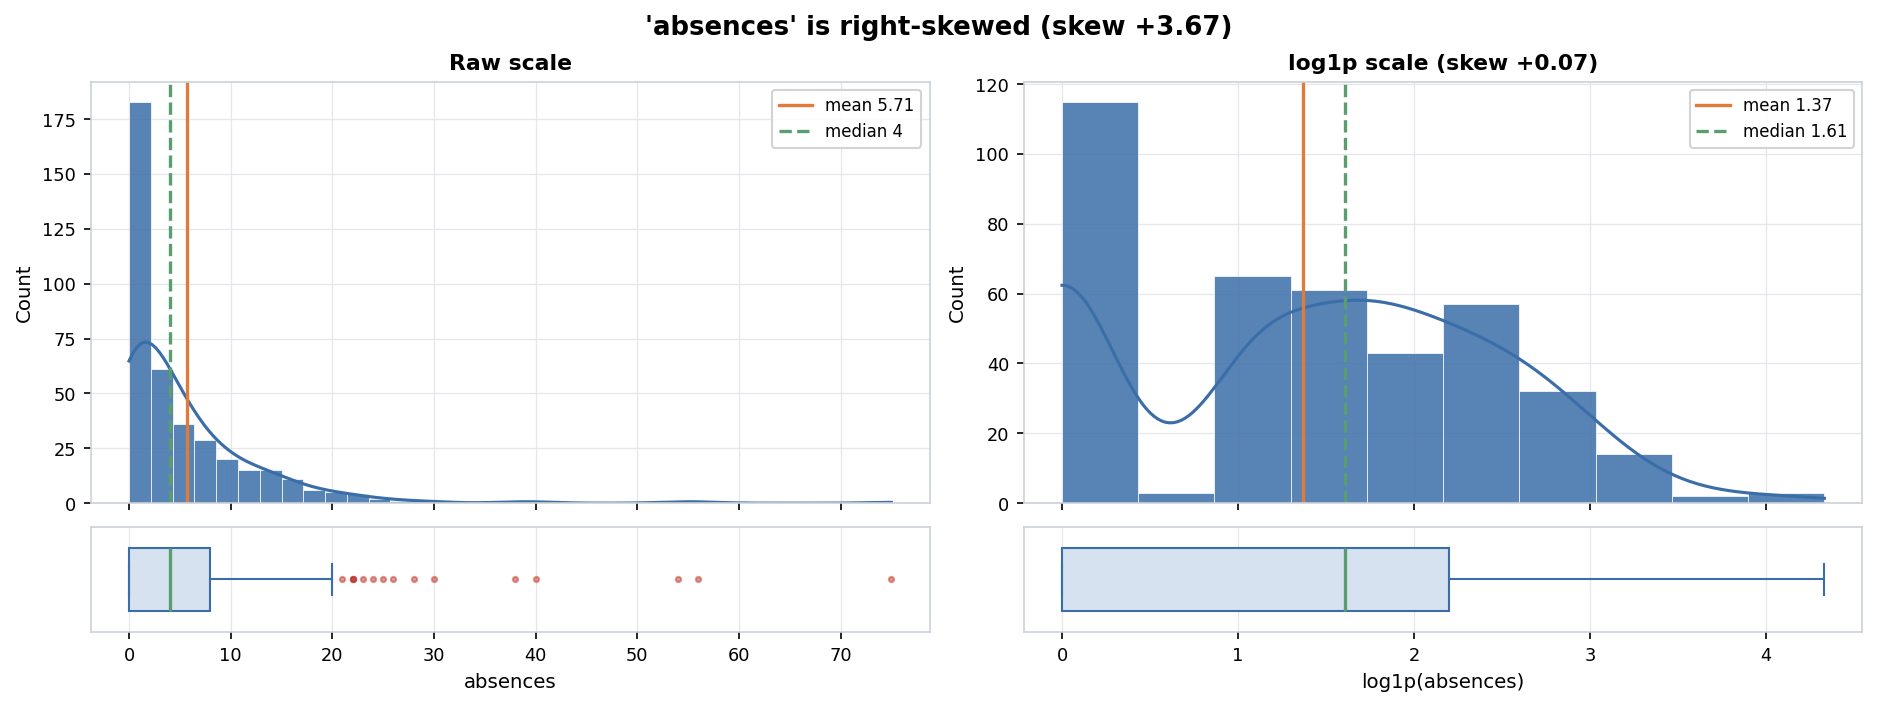

#### 'failures' is right-skewed (skew +2.39) and has 21.0% IQR outliers
*Figure 6. 'failures' is right-skewed (skew +2.39) and has 21.0% IQR outliers.* Close-up of a skewed or outlier-heavy column. The right panel shows the same values on a log1p scale.


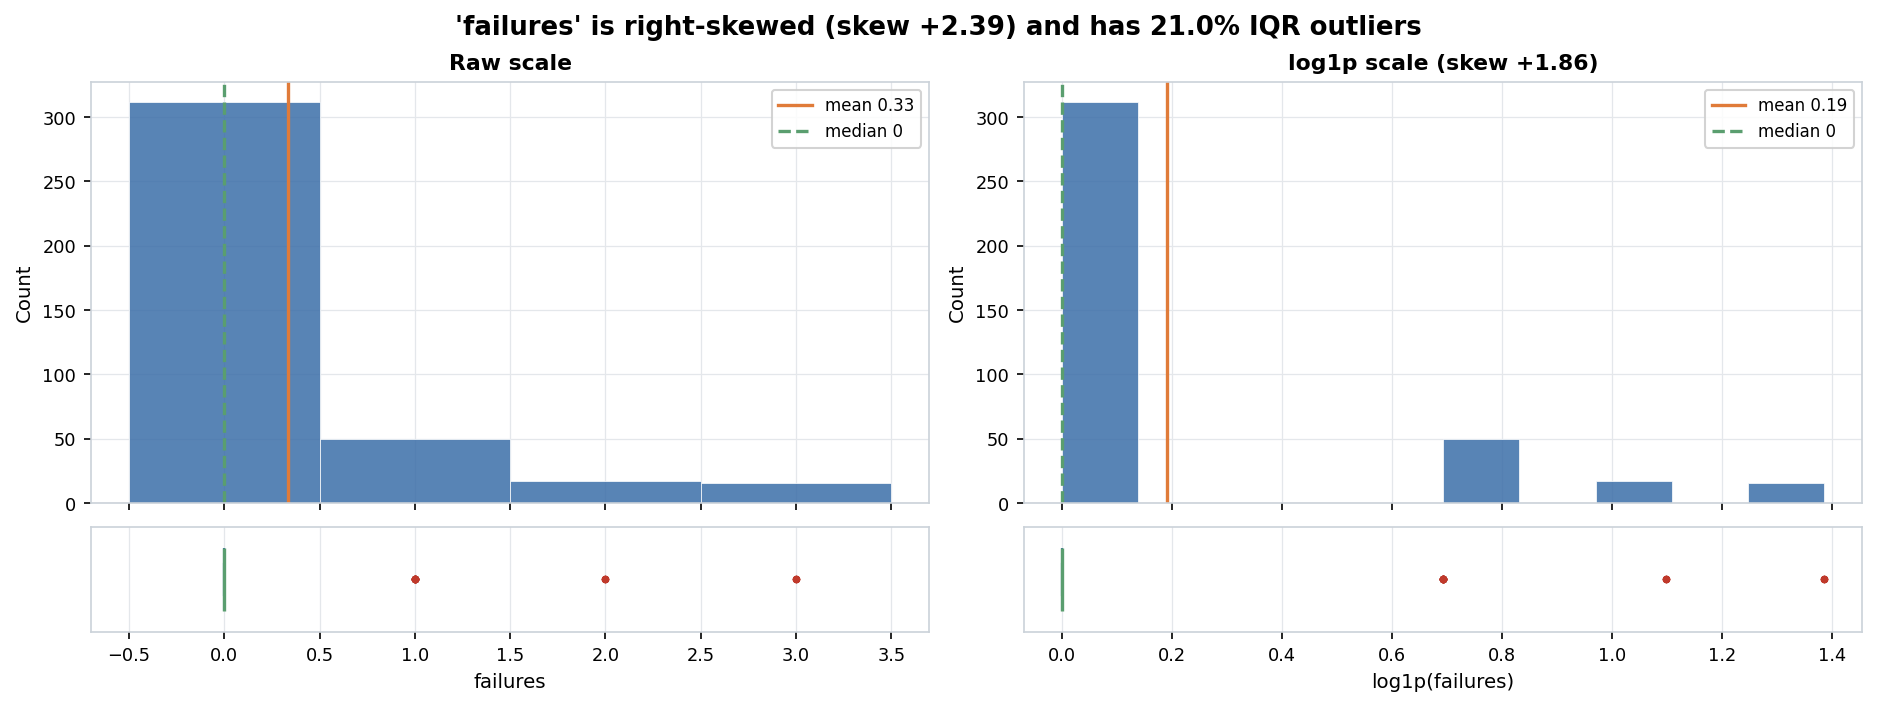

#### 'Dalc' is right-skewed (skew +2.19)
*Figure 7. 'Dalc' is right-skewed (skew +2.19).* Close-up of a skewed or outlier-heavy column. The right panel shows the same values on a log1p scale.


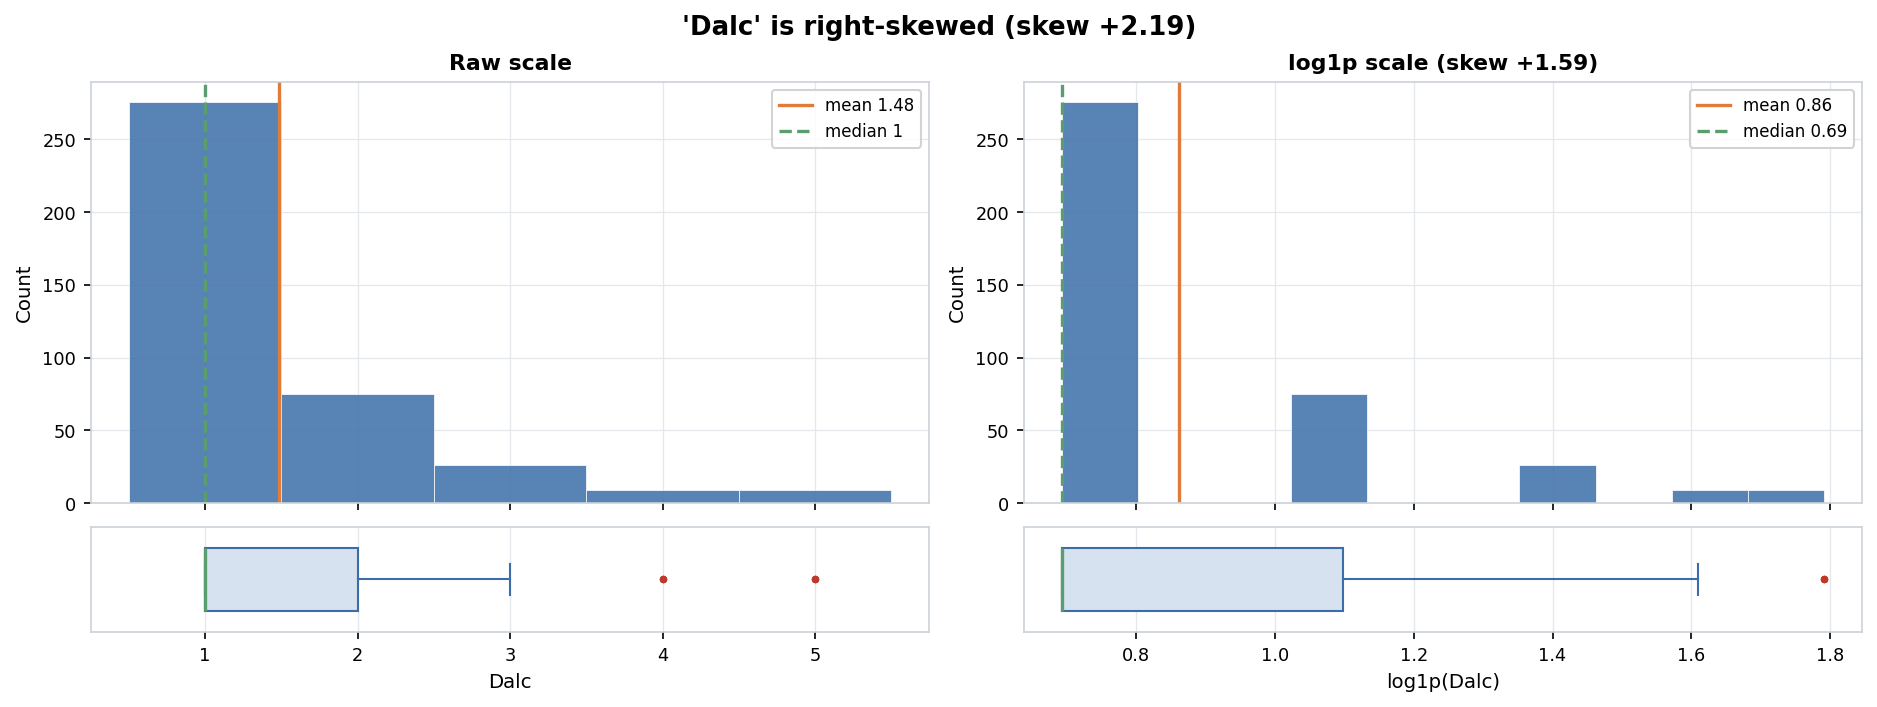

#### 'traveltime' is right-skewed (skew +1.61)
*Figure 8. 'traveltime' is right-skewed (skew +1.61).* Close-up of a skewed or outlier-heavy column. The right panel shows the same values on a log1p scale.


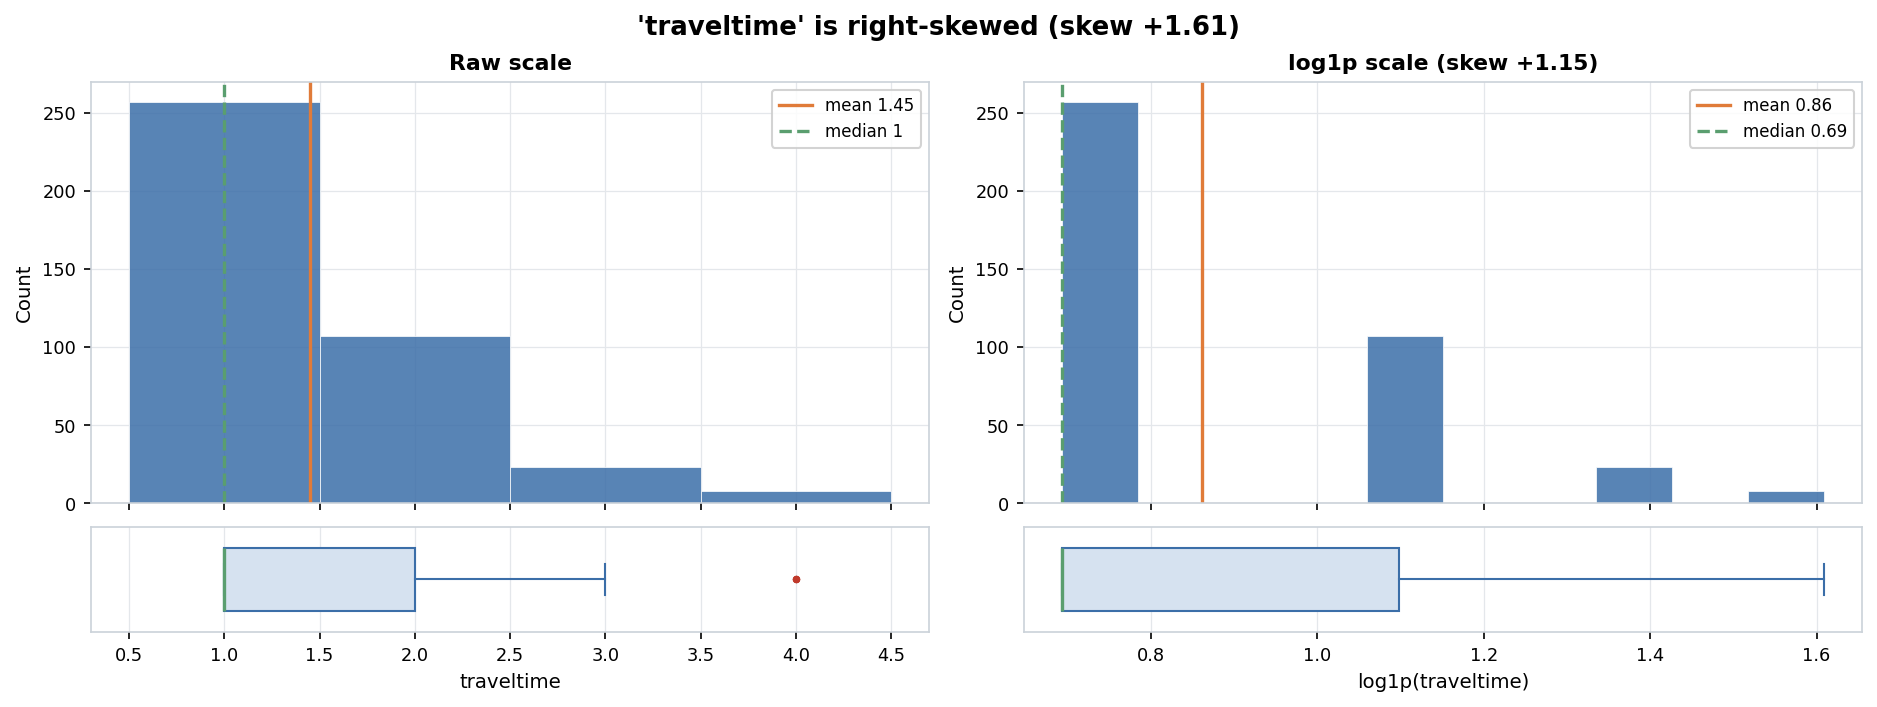

#### 'famrel' has 6.6% IQR outliers
*Figure 9. 'famrel' has 6.6% IQR outliers.* Close-up of a skewed or outlier-heavy column.


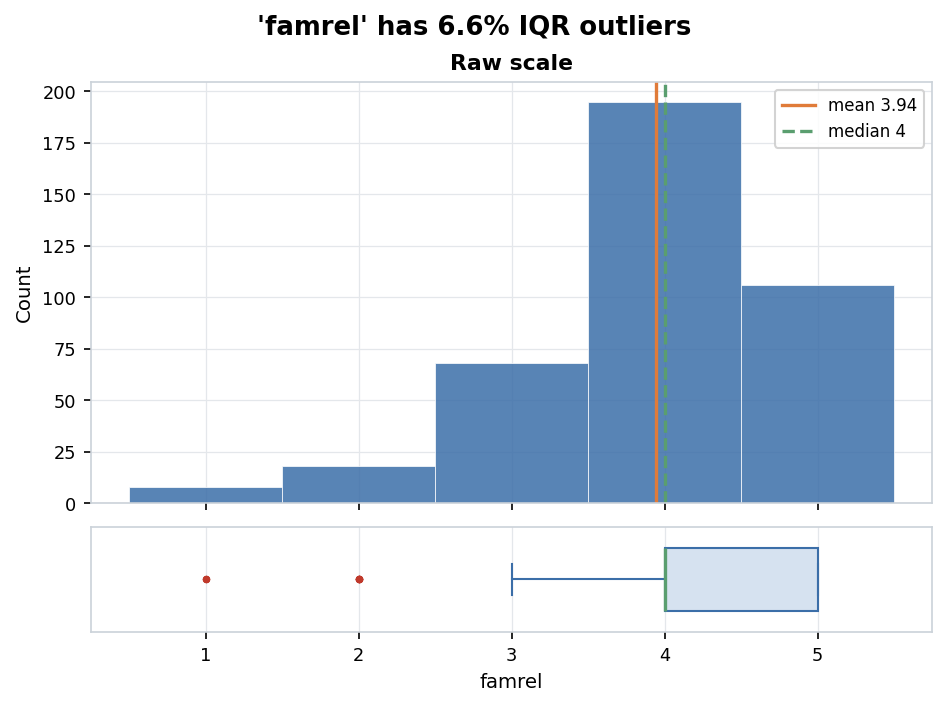

#### 'studytime' has 6.8% IQR outliers
*Figure 10. 'studytime' has 6.8% IQR outliers.* Close-up of a skewed or outlier-heavy column.


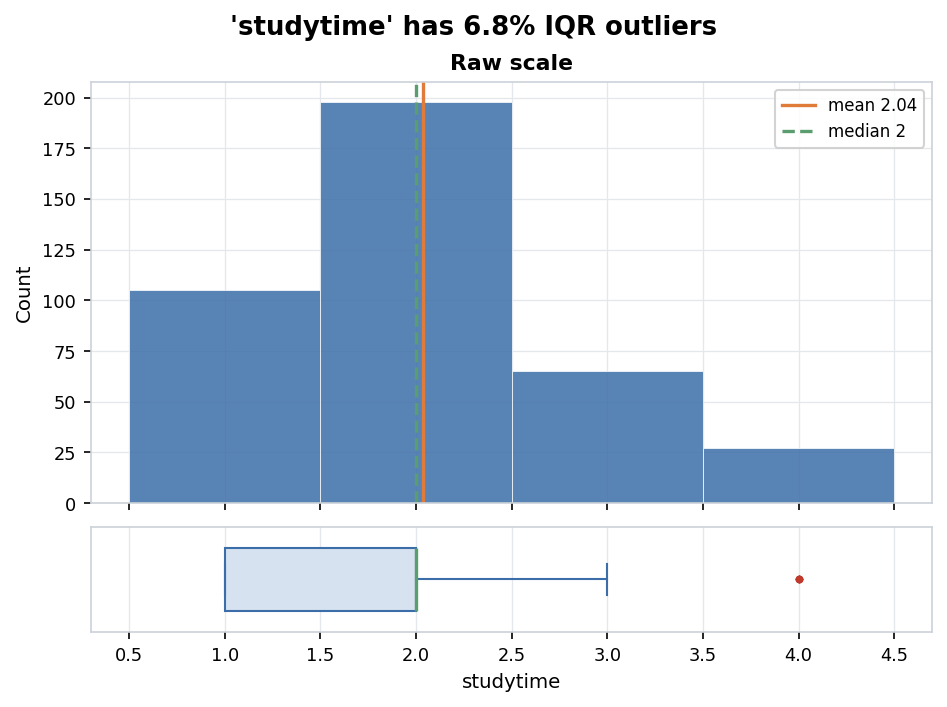

#### 'failures' has the most IQR outliers (21.0% of its values)
*Figure 11. 'failures' has the most IQR outliers (21.0% of its values).* Share of each numeric column's values outside 1.5×IQR. Outliers are only flagged, not removed, in the conservative cleaned data. Red bars are above the guide line.


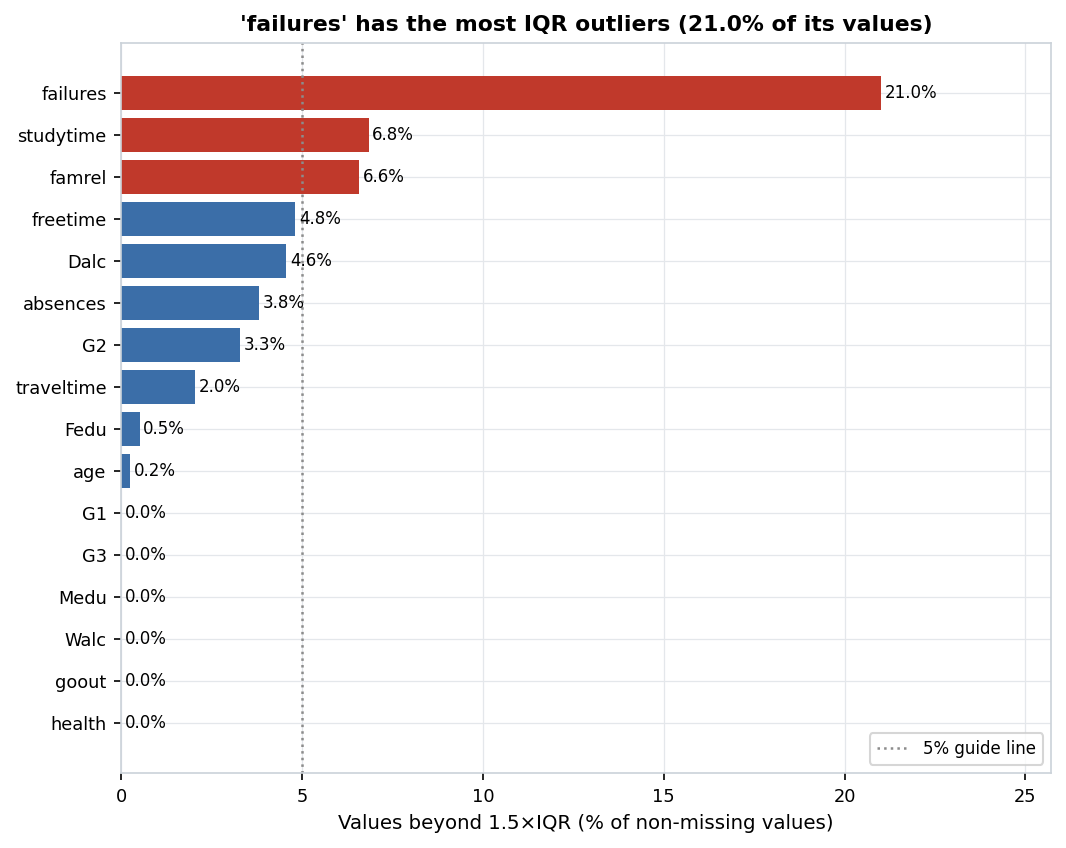

#### Categorical distributions (1/3): most lopsided here is 'Pstatus' (top level 89.6%)
*Figure 12. Categorical distributions (1/3): most lopsided here is 'Pstatus' (top level 89.6%).* Share of rows per level (top 15 levels; the rest are grouped as 'Other'). The orange bar marks the smallest (minority) level.


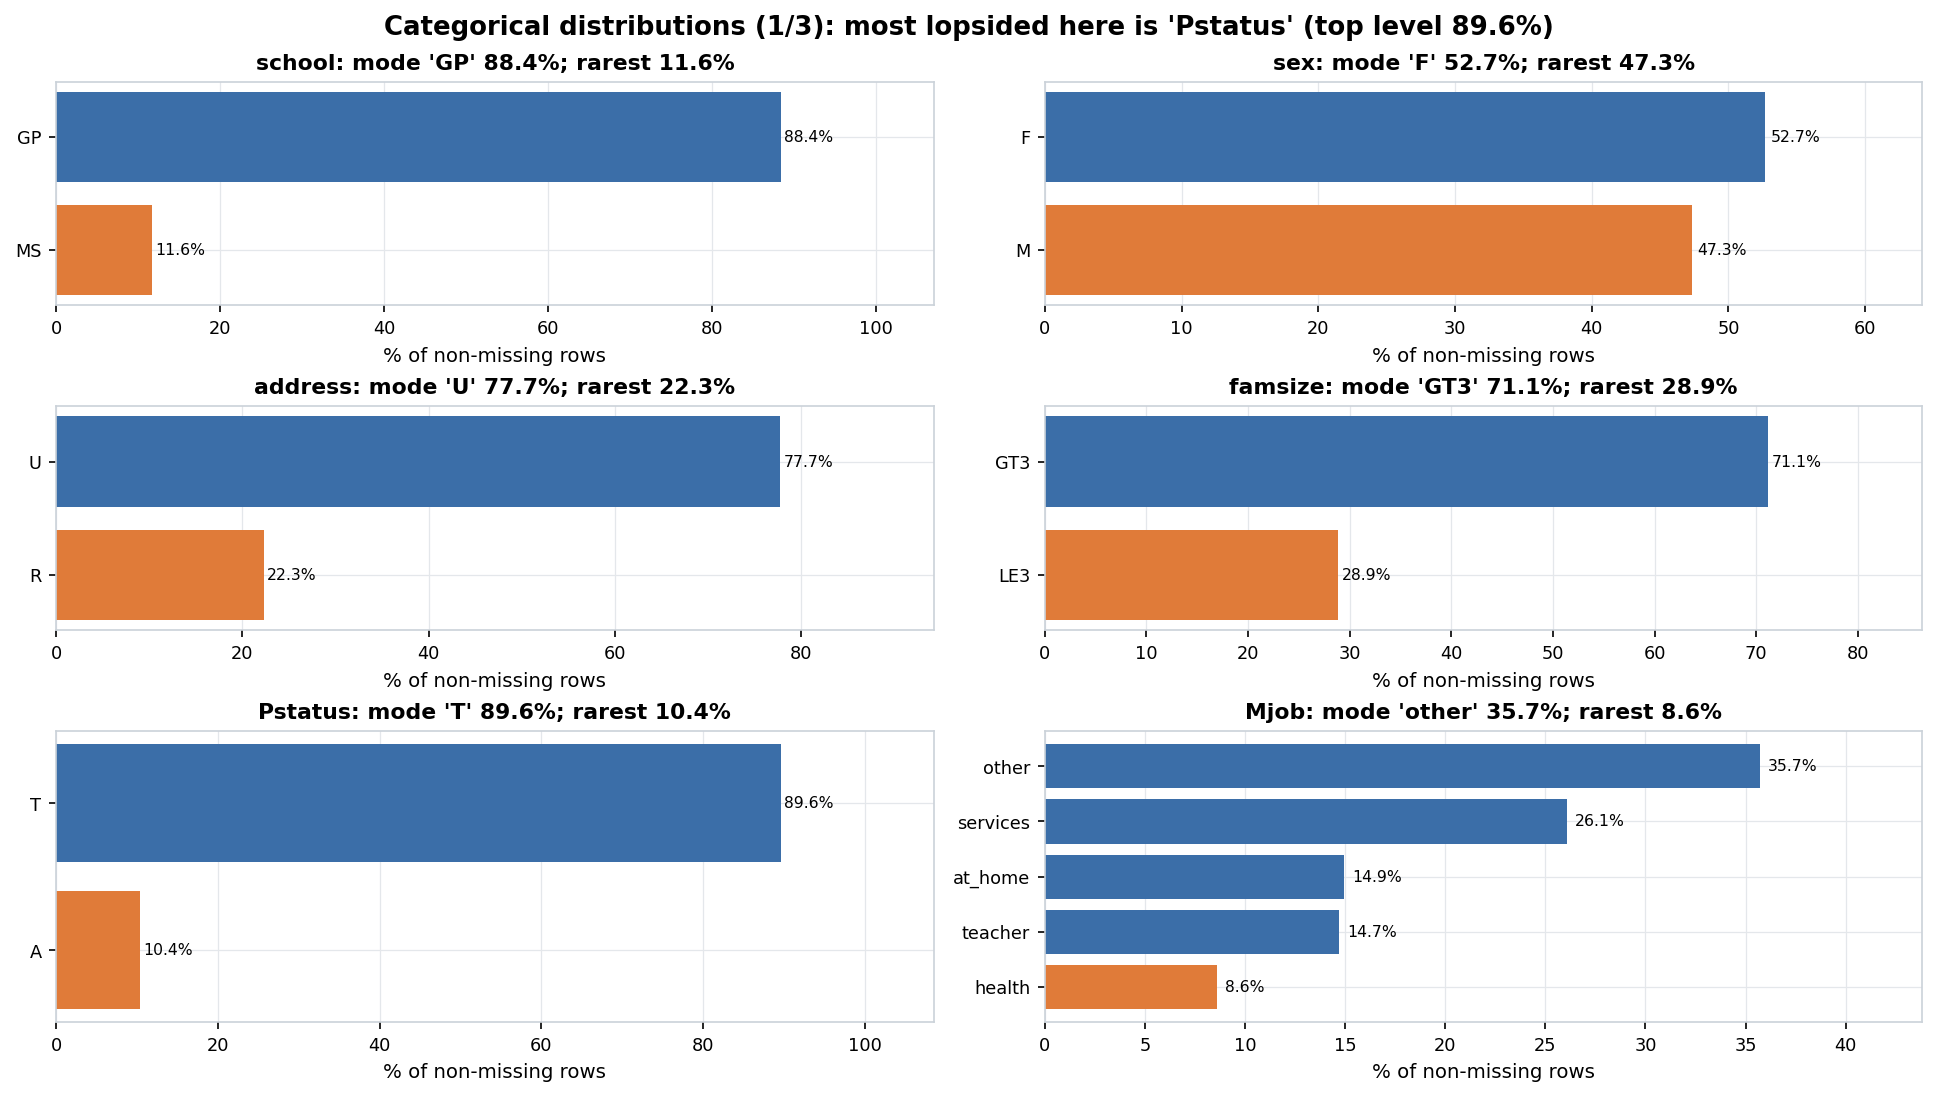

#### Categorical distributions (2/3): most lopsided here is 'schoolsup' (top level 87.1%)
*Figure 13. Categorical distributions (2/3): most lopsided here is 'schoolsup' (top level 87.1%).* Share of rows per level (top 15 levels; the rest are grouped as 'Other'). The orange bar marks the smallest (minority) level.


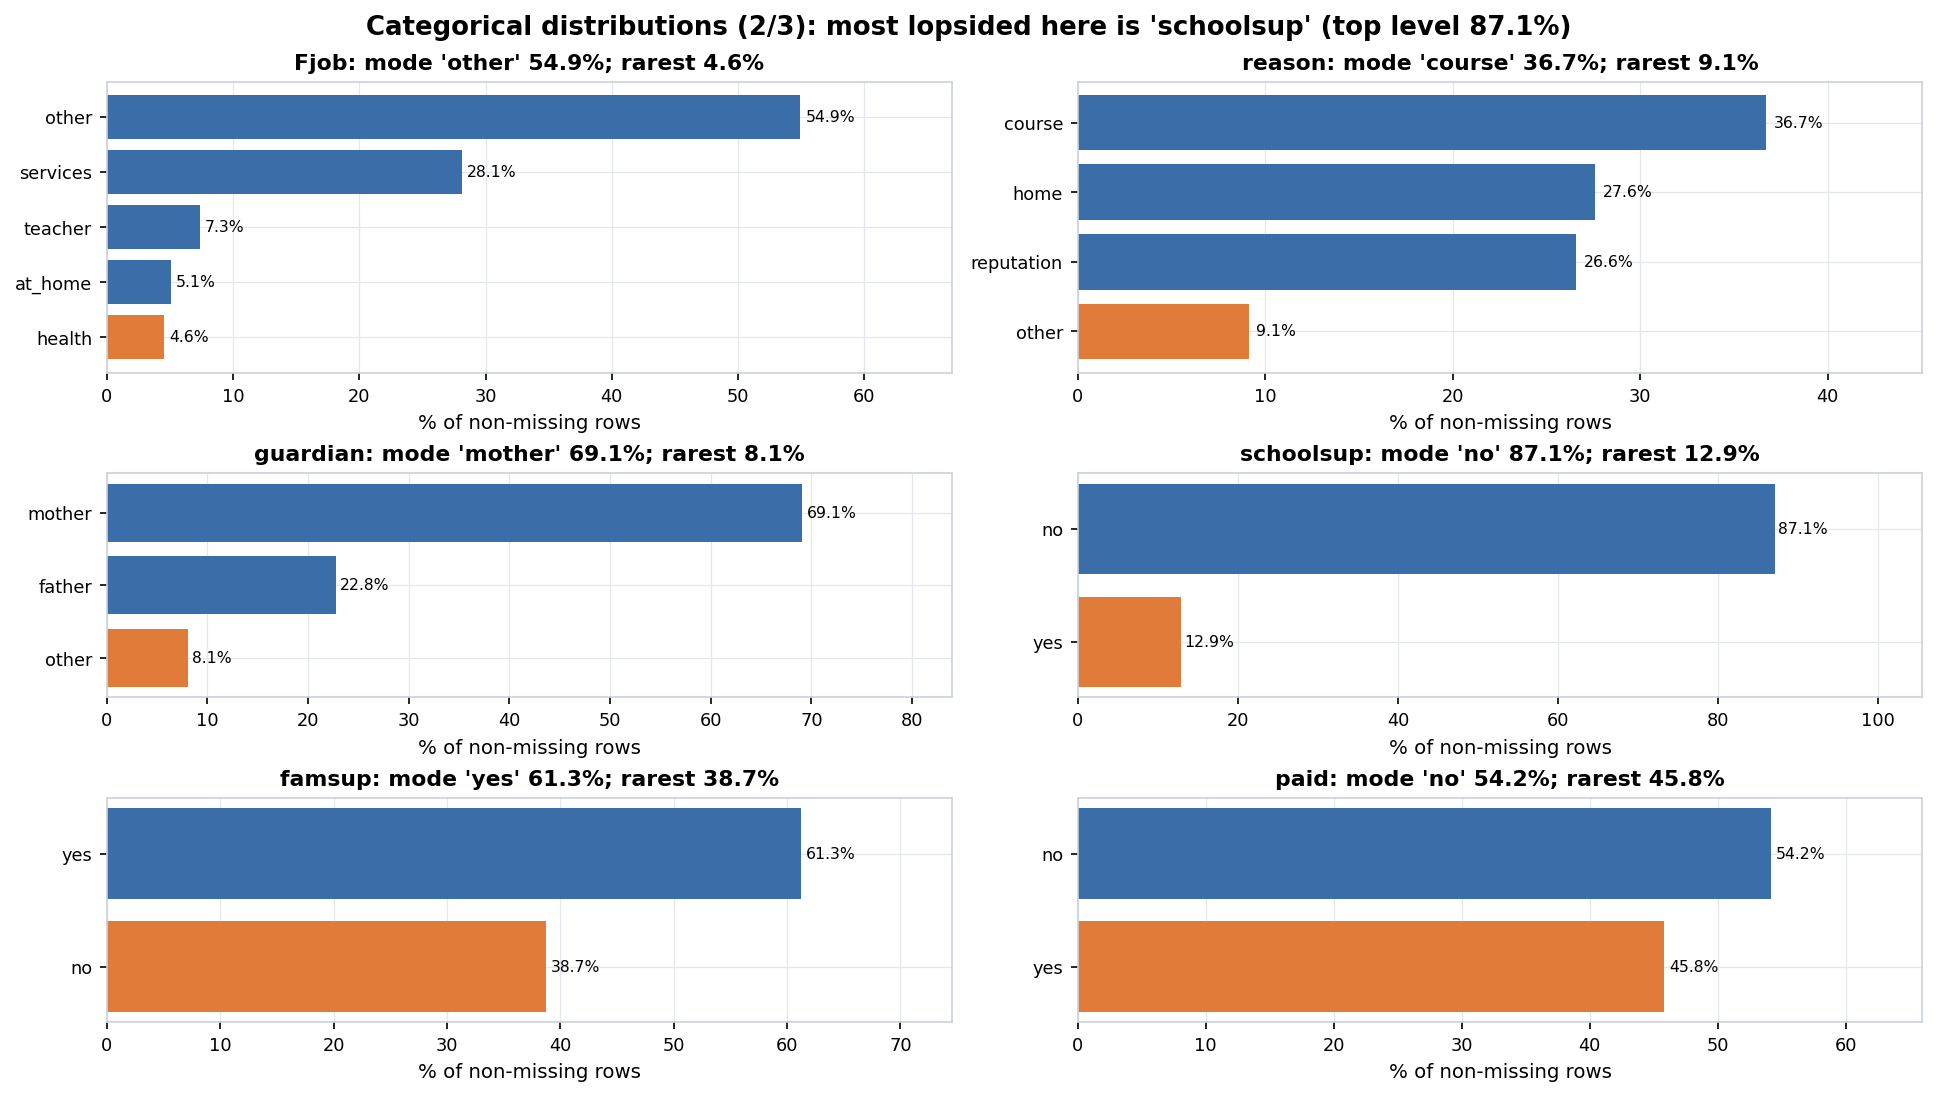

#### Categorical distributions (3/3): most lopsided here is 'higher' (top level 94.9%)
*Figure 14. Categorical distributions (3/3): most lopsided here is 'higher' (top level 94.9%).* Share of rows per level (top 15 levels; the rest are grouped as 'Other'). The orange bar marks the smallest (minority) level.


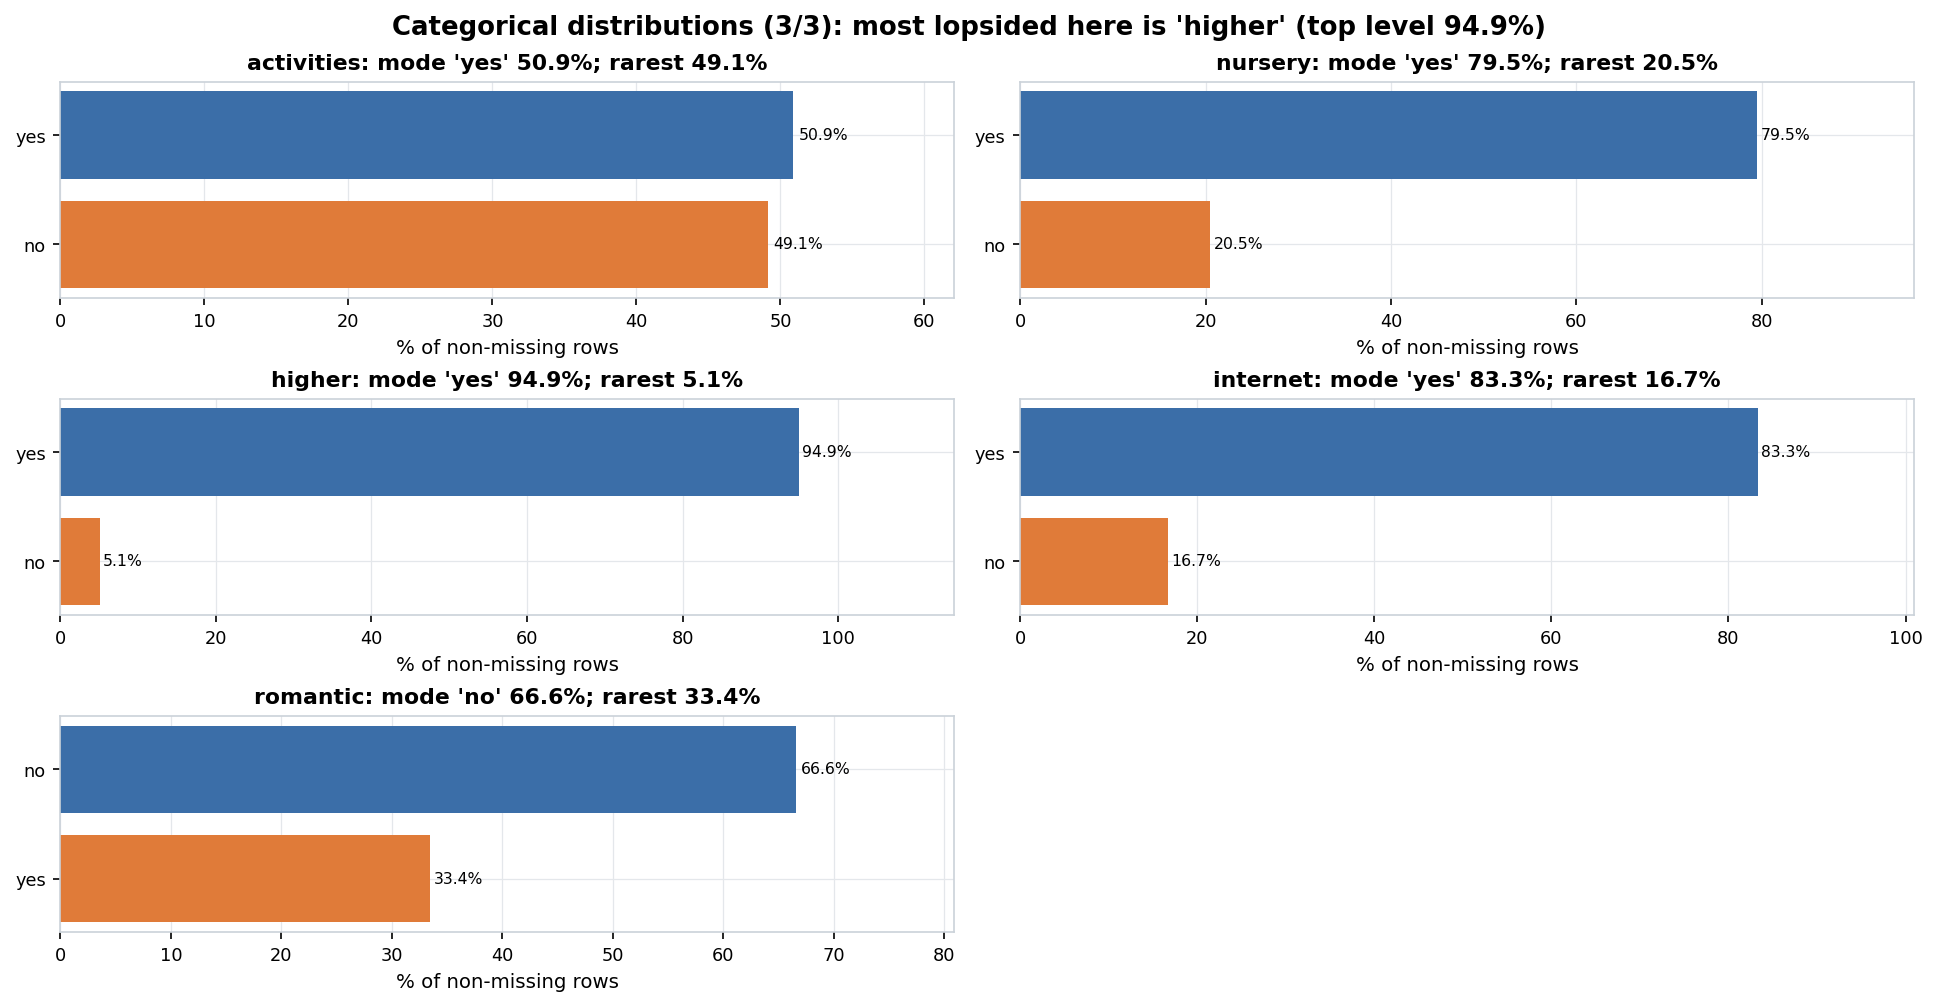

#### 'Fjob' has the most levels (5)
*Figure 15. 'Fjob' has the most levels (5).* Number of distinct values in each categorical or binary column.


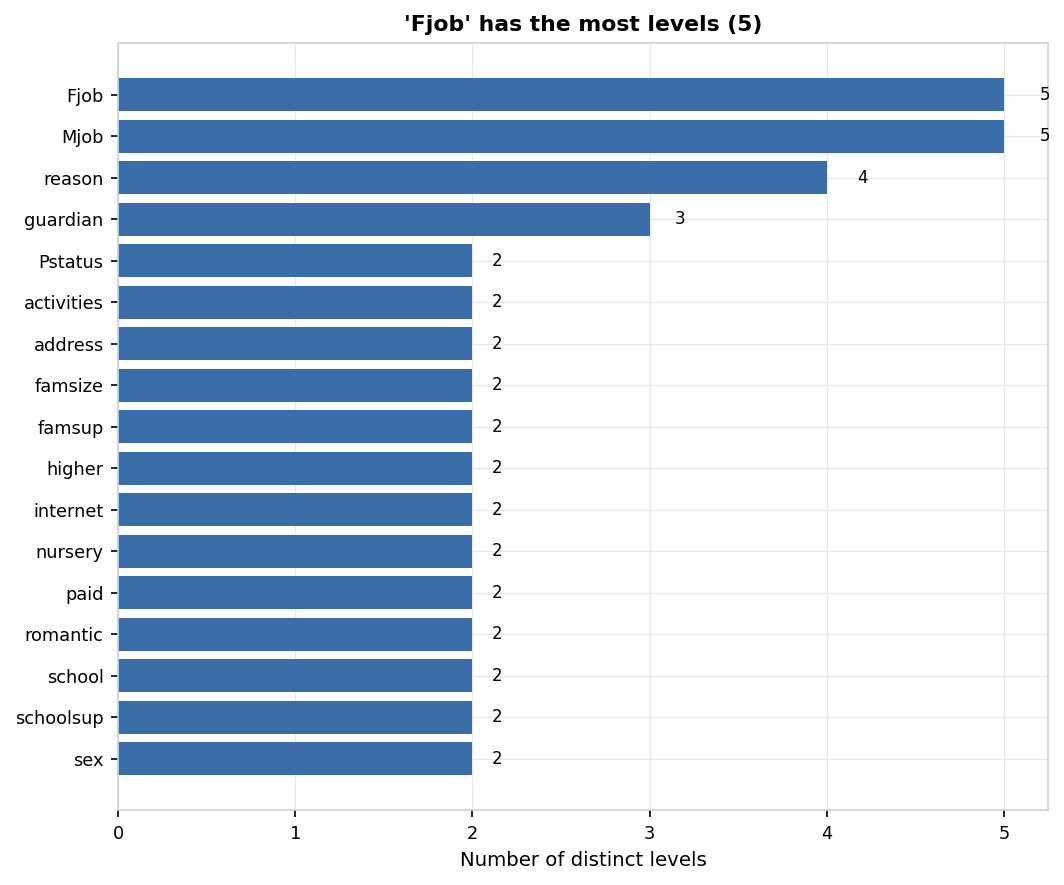

#### Target 'G3' ranges from 0 to 20 (median 11, skew -0.73)
*Figure 16. Target 'G3' ranges from 0 to 20 (median 11, skew -0.73).* Distribution of the target column.


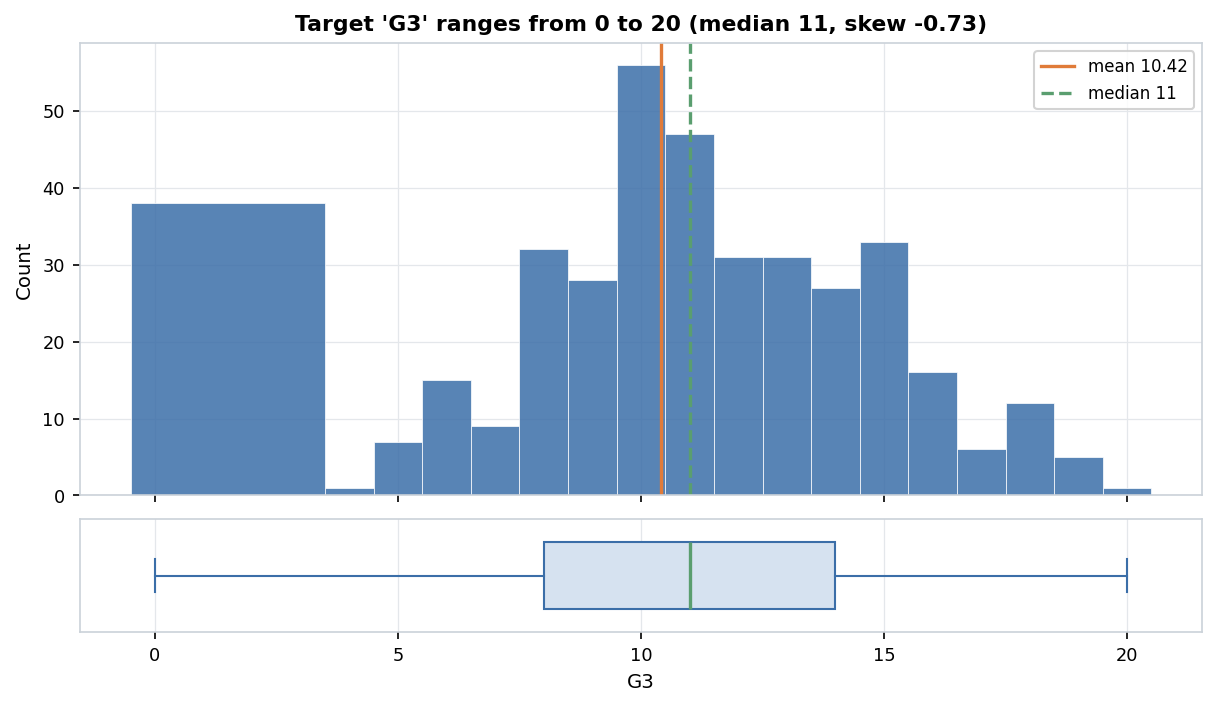

#### Strongest numeric pair: 'G2' vs 'G3' (Spearman +0.96, Pearson +0.91)
*Figure 17. Strongest numeric pair: 'G2' vs 'G3' (Spearman +0.96, Pearson +0.91).* Correlation between numeric columns (lower triangle). Left: Pearson (linear). Right: Spearman (rank-based). Descriptive coefficients only; no hypothesis tests were run.


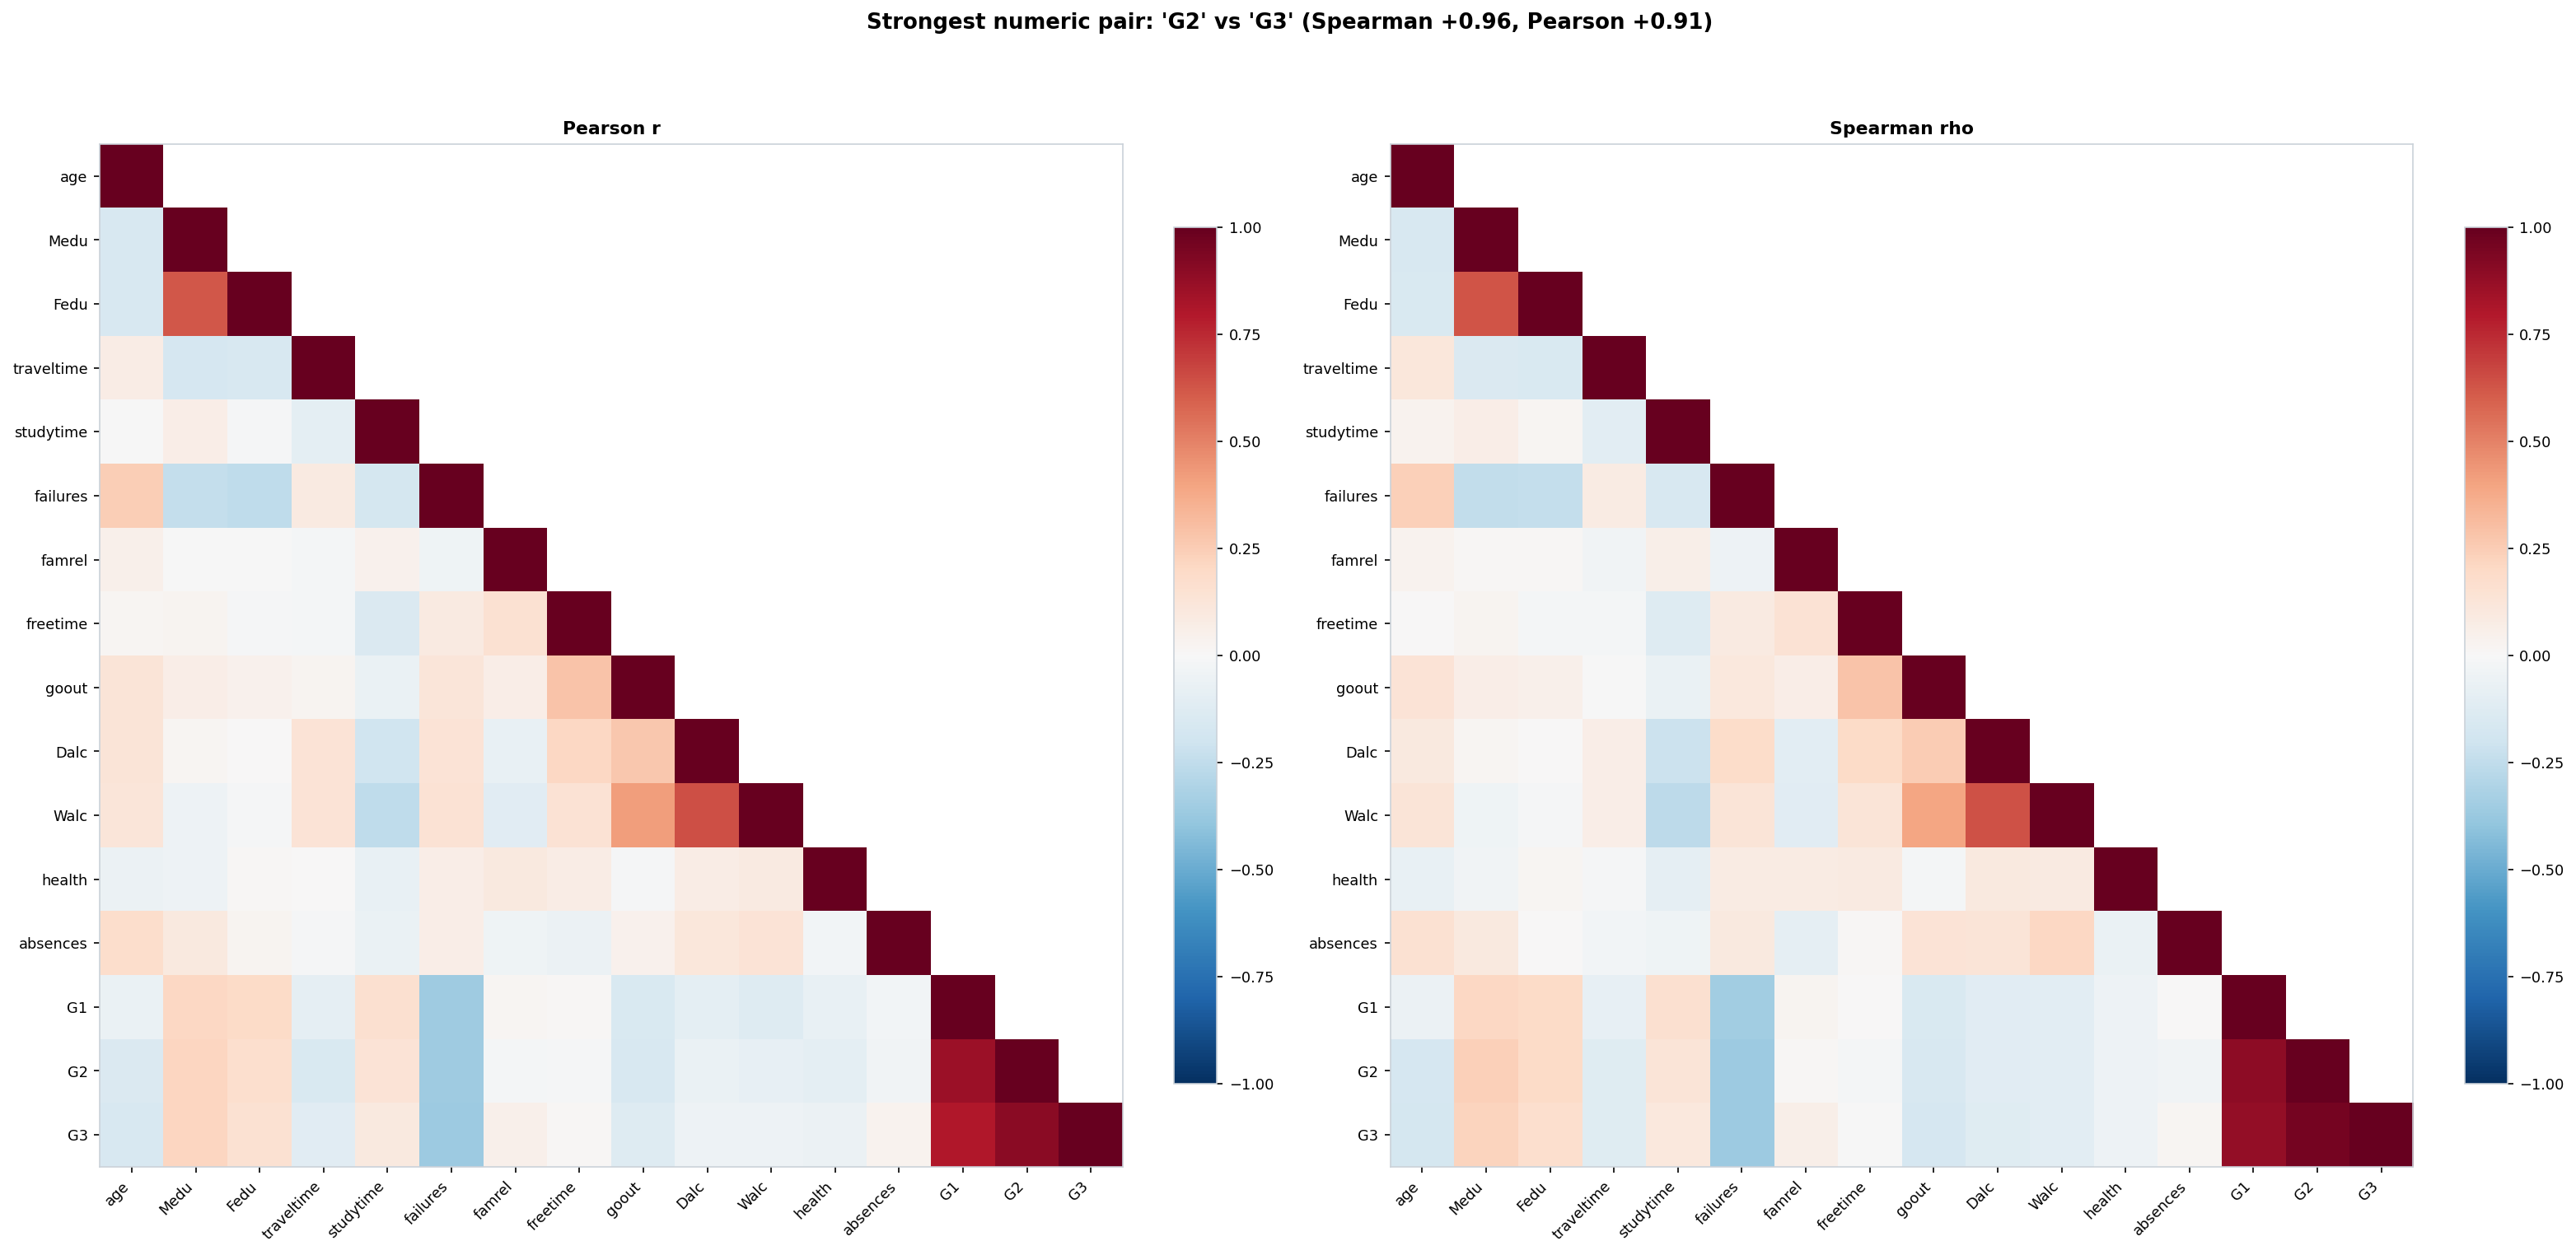

#### Top 6 numeric pairs by |Spearman rho|
*Figure 18. Top 6 numeric pairs by |Spearman rho|.* Scatter plots with a straight-line fit for the most strongly related numeric pairs. Large datasets are randomly sampled for plotting. Descriptive coefficients only; no hypothesis tests were run.


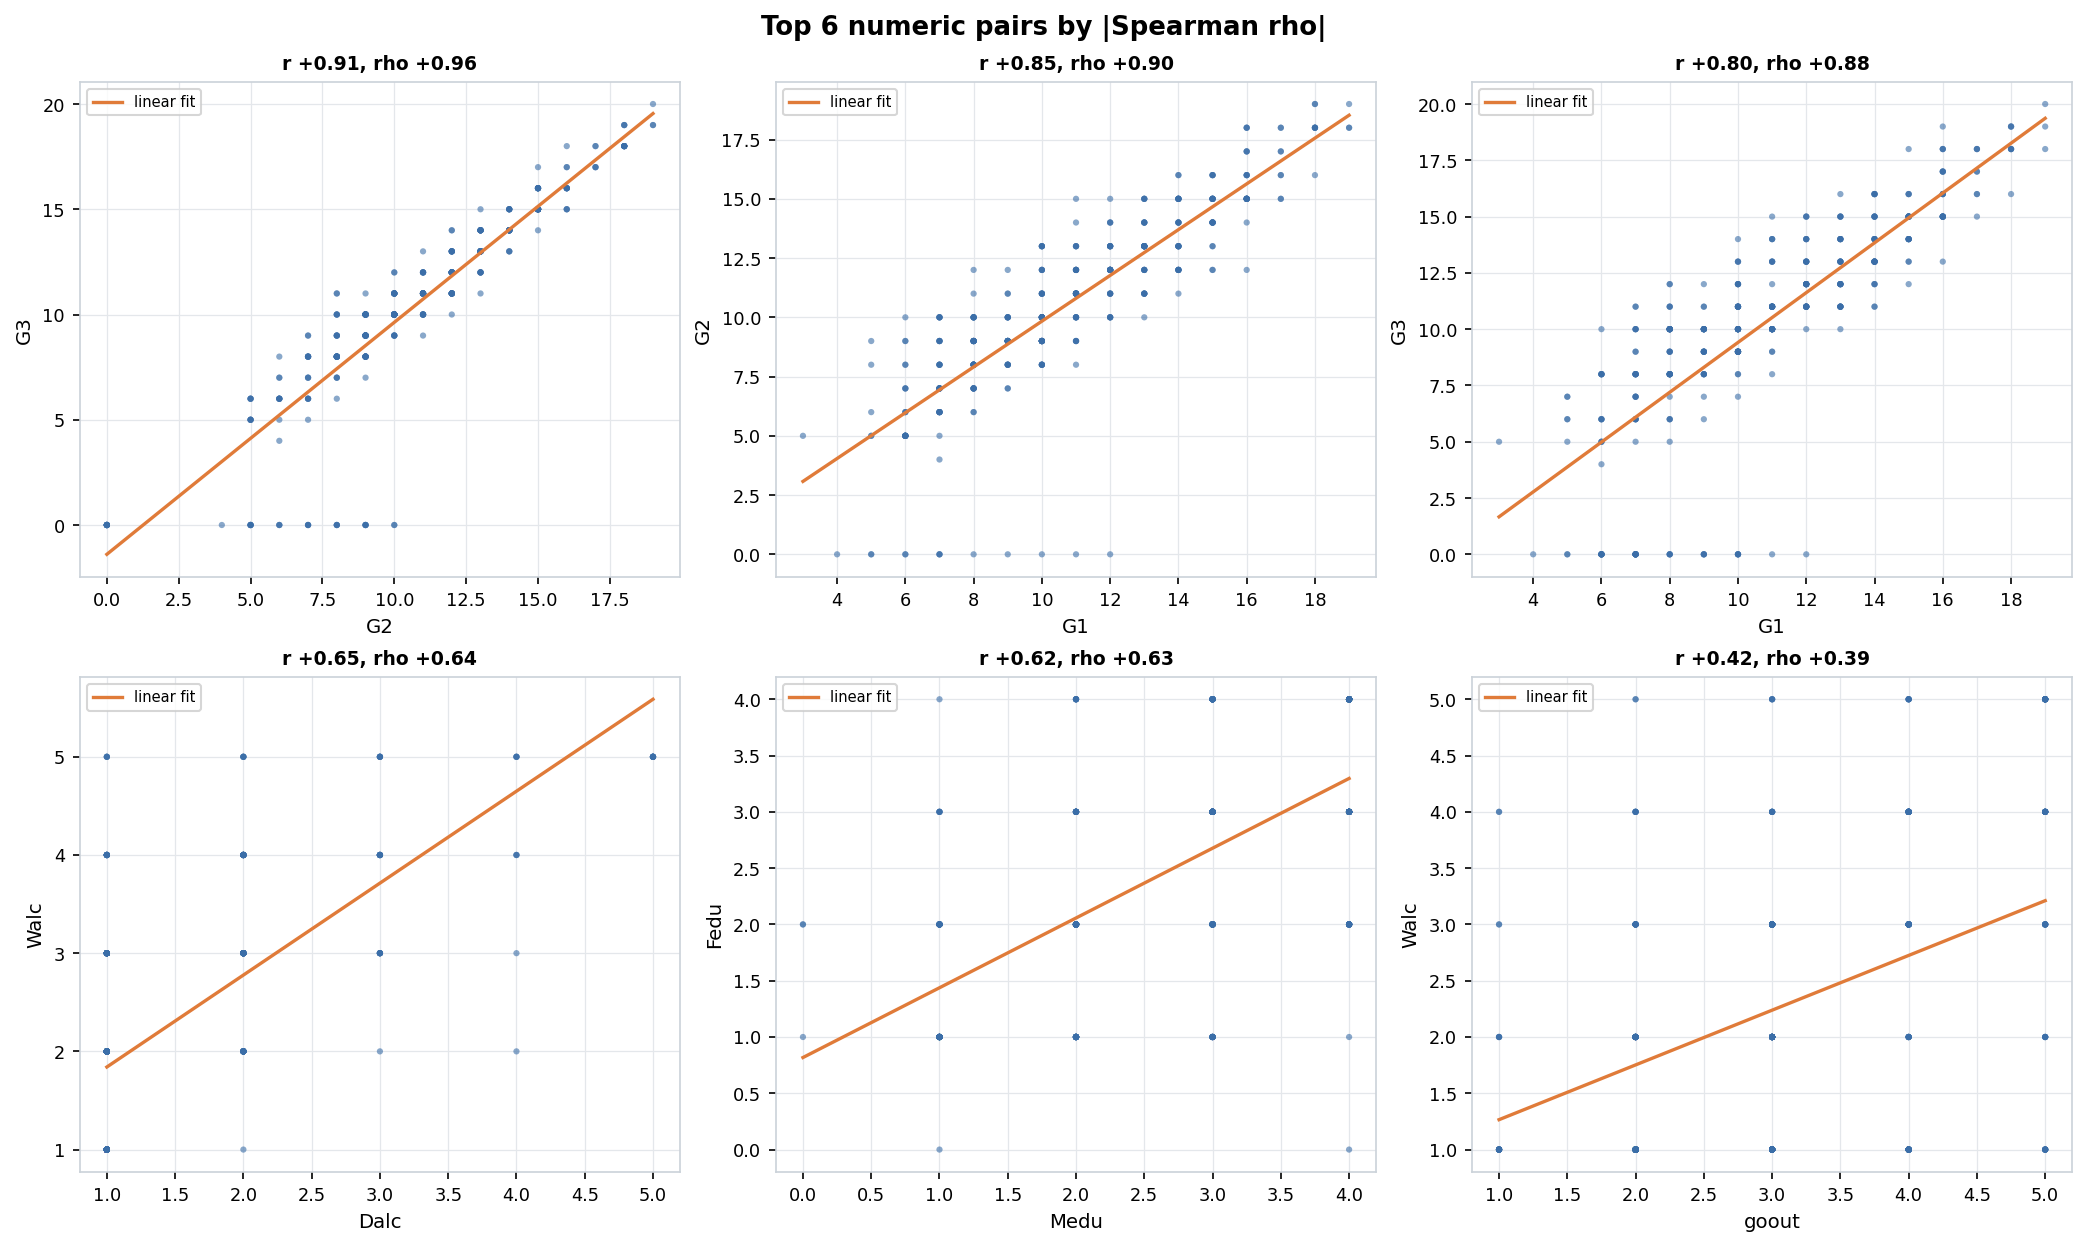

#### 'Mjob' separates 'Medu' the most (eta² 0.41 = share of its spread explained by the groups)
*Figure 19. 'Mjob' separates 'Medu' the most (eta² 0.41 = share of its spread explained by the groups).* Box plots of numeric columns split by categorical columns with up to 8 levels, for the pairs with the largest eta-squared. Descriptive coefficients only; no hypothesis tests were run.


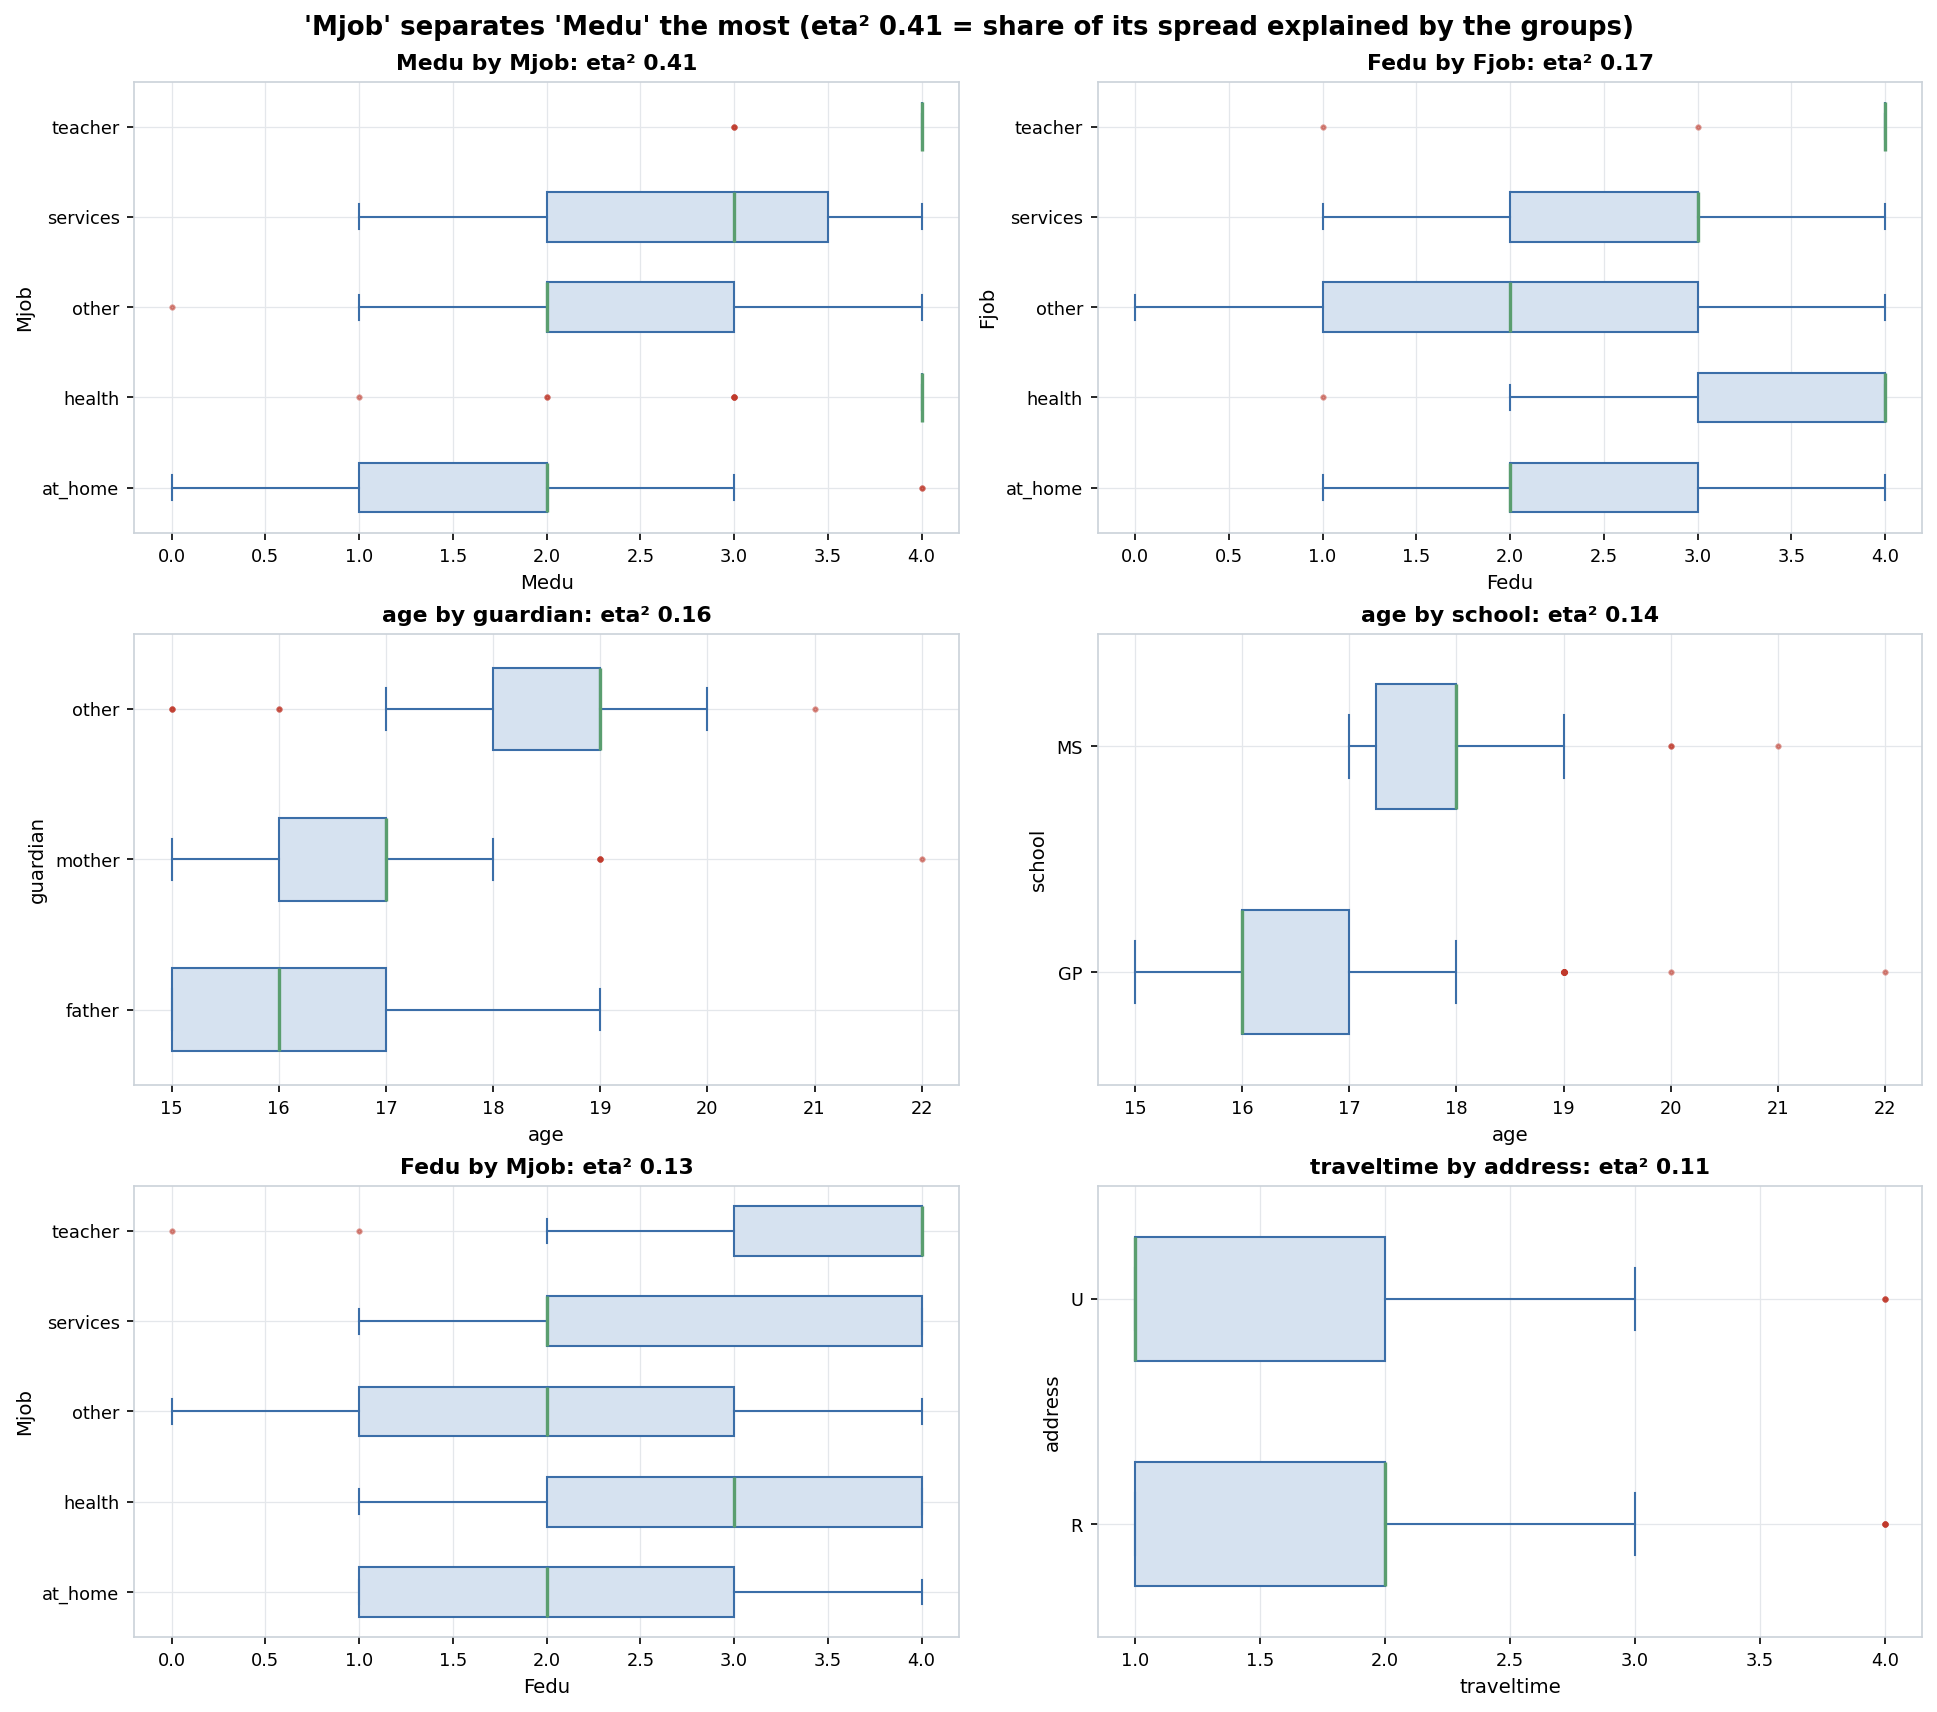

#### Strongest categorical pair: 'famsup' vs 'paid' (Cramér's V 0.29)
*Figure 20. Strongest categorical pair: 'famsup' vs 'paid' (Cramér's V 0.29).* Bias-corrected Cramér's V between categorical/binary columns: 0 = unrelated, 1 = one fully predicts the other. Descriptive coefficients only; no hypothesis tests were run.


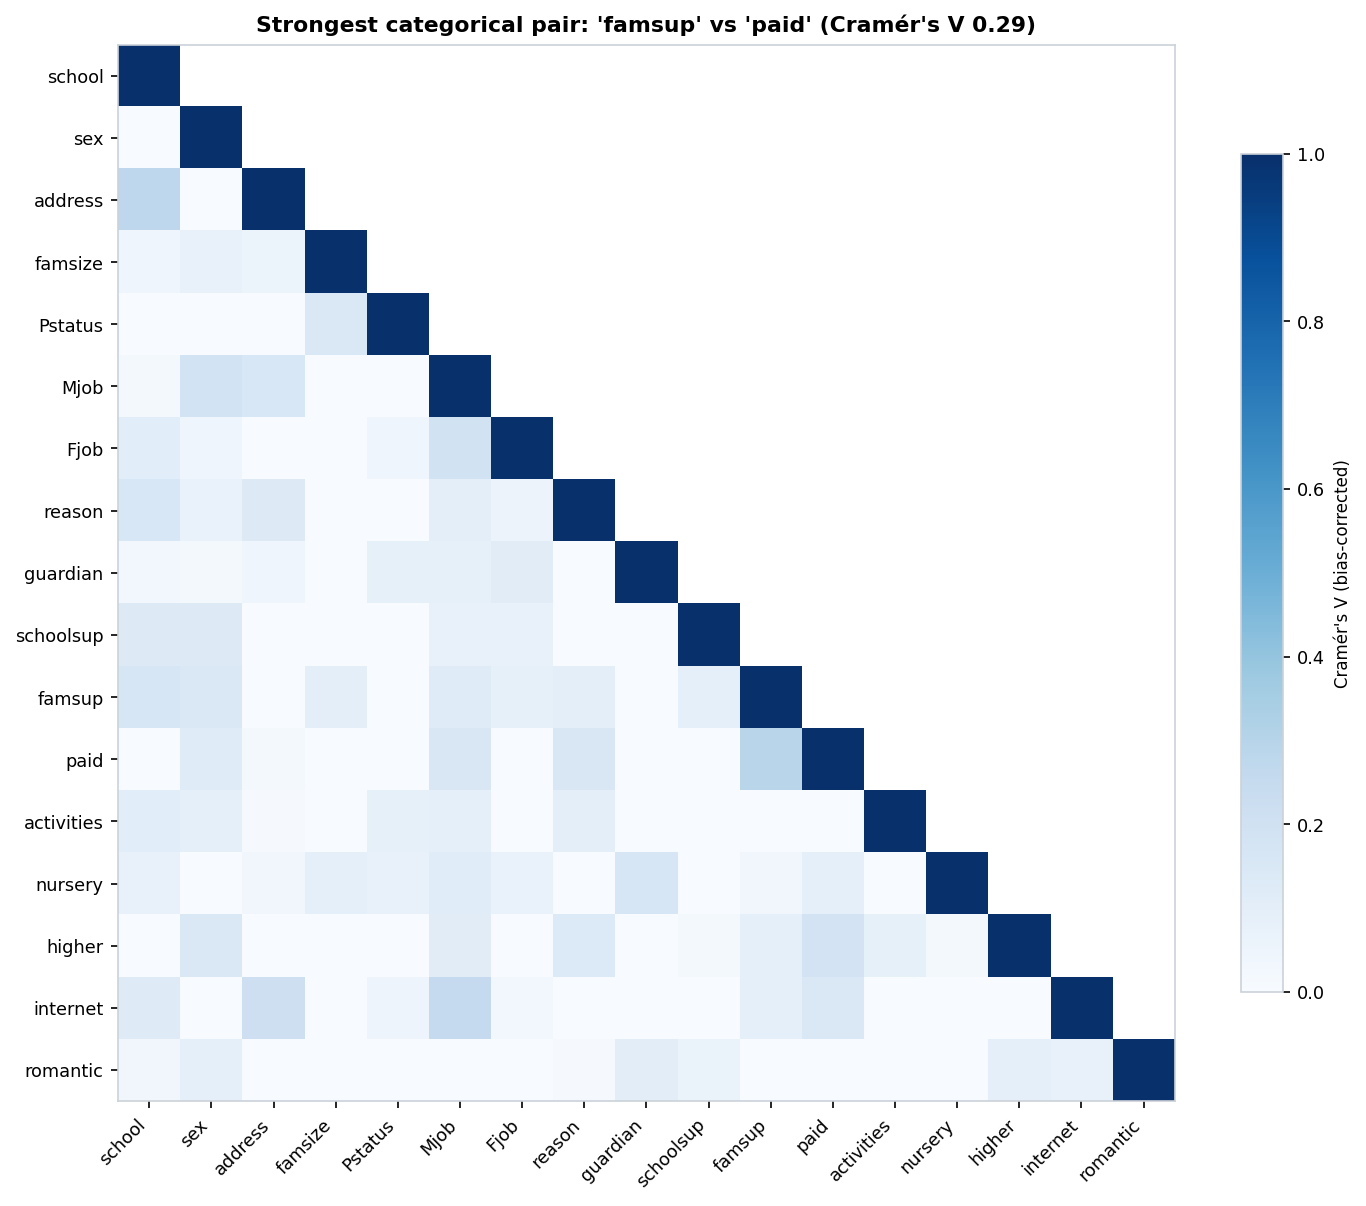

#### Level-by-level mix for the most associated categorical pairs
*Figure 21. Level-by-level mix for the most associated categorical pairs.* For each level of the first column, the share of rows in each level of the second column. Descriptive coefficients only; no hypothesis tests were run.


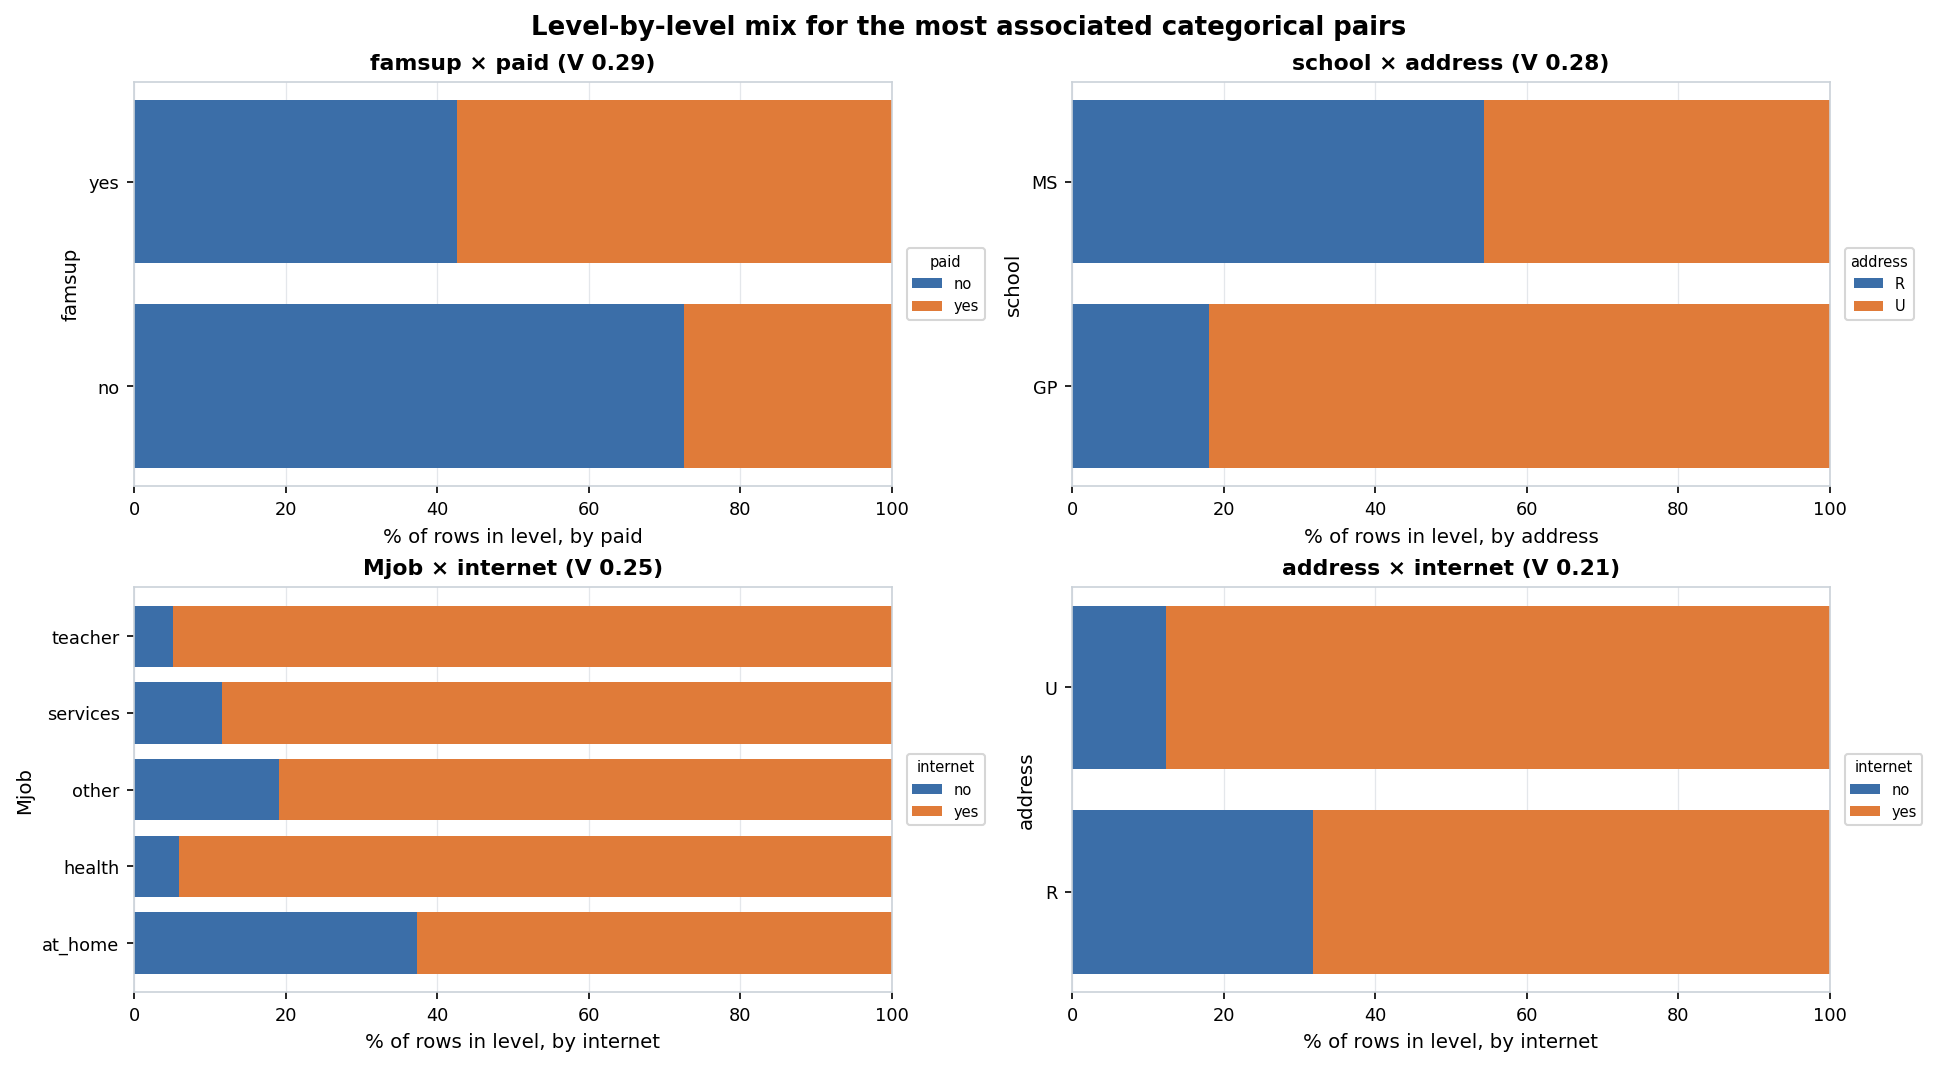

#### 'G2' has the strongest association with 'G3' (Spearman rho 0.96)
*Figure 22. 'G2' has the strongest association with 'G3' (Spearman rho 0.96).* Every feature ranked by a descriptive association with the target. Different measures are used for different column types, so compare bars of the same colour most directly. Descriptive coefficients only; no hypothesis tests were run.


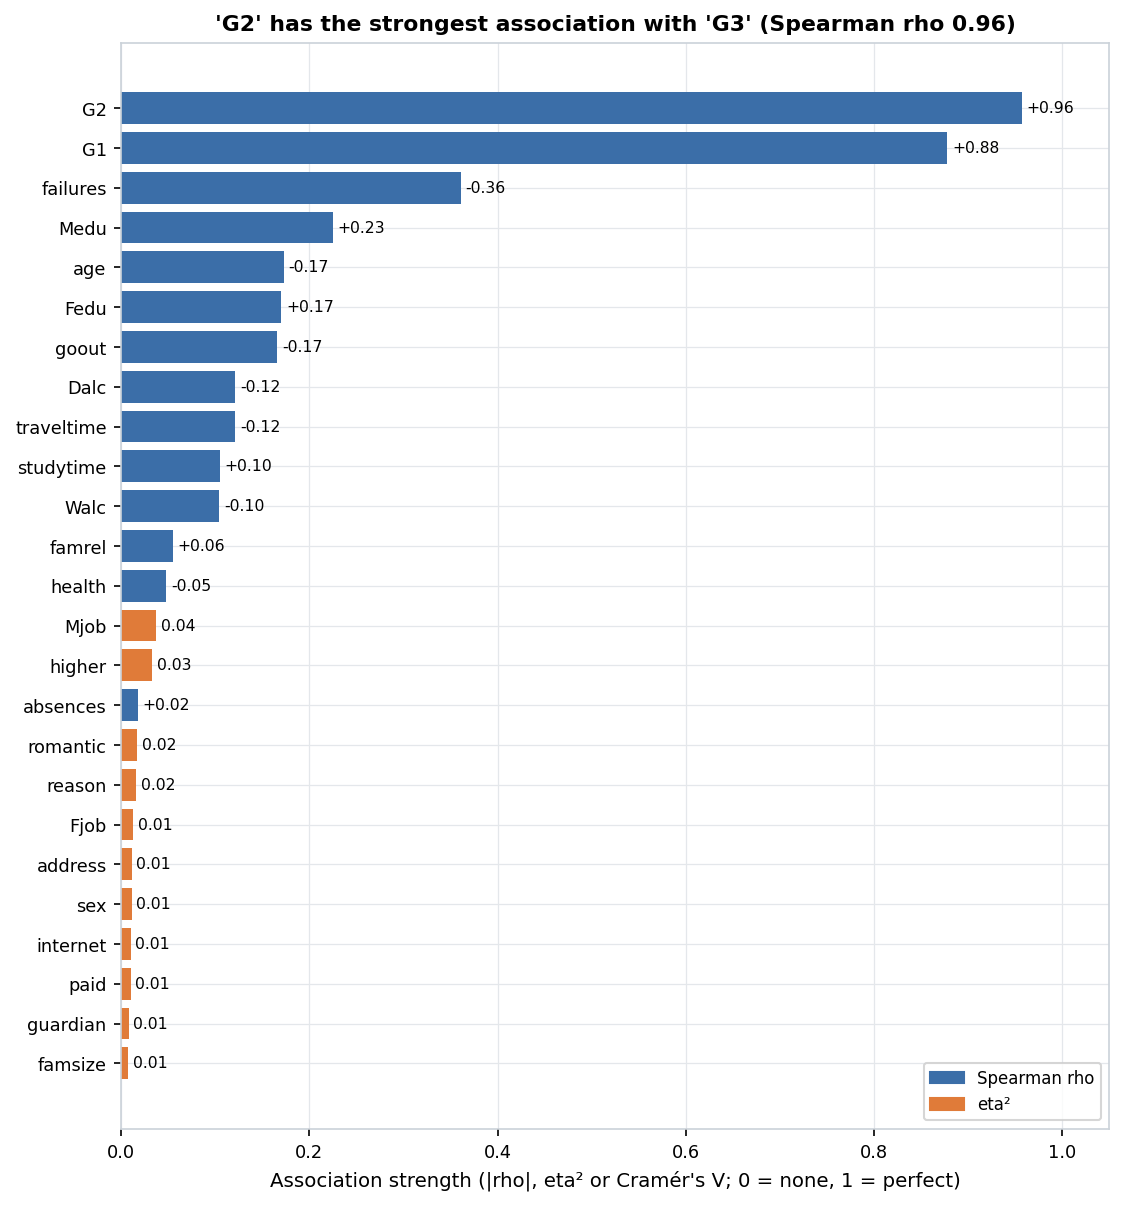

In [4]:
# Display all generated EDA figures and their interpretive captions from outputs/<dataset>/figures/
for png_path in sorted((OUT_DIR / "figures").glob("*.png")):
    display(Markdown(f"### `{png_path.name}`"))
    display(Image(filename=str(png_path)))

## 5. Normalization & Scaling Analysis
**What we did & why:** We evaluated skewness and scale disparity across all numeric columns (`ads.scaling.analyze_scaling`). Right-skewed positive columns (`|skew| > 1.0`, `min >= 0`) are recommended for `log1p` transformation, skewed columns with negative values use `yeo_johnson`, and high scale disparity triggers `zscore` standardization in `<dataset>_scaled.csv` for scale-sensitive models while keeping the primary cleaned dataset unscaled.

In [5]:
display(Markdown((OUT_DIR / "scaling_report.md").read_text(encoding="utf-8")))

# Scaling & Transformation Analysis — `student_performance`

## Decision Summary

> Primary cleaned output is **not** scaled. The Phase 3 test library is rank-based or scale-invariant (Welch/Mann-Whitney, Spearman, Kruskal, chi-square), so scaling would not change results. Log transforms are recommended for columns [traveltime, failures, Dalc, absences] only for plotting and for parametric/regression use. A scaled copy is provided for TA review and for any future modeling.

## Scale Disparity Across Numeric Features

- **Max standard deviation:** `8.0031`
- **Min standard deviation:** `0.6975`
- **Scale disparity ratio (`max_std / min_std`):** `11.47x`
- **Z-score standardization recommended for scale-sensitive models (PCA/L1/L2/KNN):** `True`

## Per-Column Transformation Recommendations

| Column | Skewness | Kurtosis | Min | Max | Std | Min >= 0 | Recommended Transform | Reason |
| :--- | ---: | ---: | ---: | ---: | ---: | :---: | :--- | :--- |
| `age` | 0.466 | -0.001 | 15 | 22 | 1.276 | True | `none` | Moderate/low skewness (skew=0.47); no non-linear transform needed. |
| `Medu` | -0.318 | -1.090 | 0 | 4 | 1.095 | True | `none` | Moderate/low skewness (skew=-0.32); no non-linear transform needed. |
| `Fedu` | -0.032 | -1.199 | 0 | 4 | 1.088 | True | `none` | Moderate/low skewness (skew=-0.03); no non-linear transform needed. |
| `traveltime` | 1.607 | 2.344 | 1 | 4 | 0.698 | True | `log1p` | Right-skewed (skew=1.61 > 1.0) with non-negative domain (min=1); log1p recommended. |
| `studytime` | 0.632 | -0.014 | 1 | 4 | 0.839 | True | `none` | Moderate/low skewness (skew=0.63); no non-linear transform needed. |
| `failures` | 2.387 | 5.005 | 0 | 3 | 0.744 | True | `log1p` | Right-skewed (skew=2.39 > 1.0) with non-negative domain (min=0); log1p recommended. |
| `famrel` | -0.952 | 1.140 | 1 | 5 | 0.897 | True | `none` | Moderate/low skewness (skew=-0.95); no non-linear transform needed. |
| `freetime` | -0.163 | -0.302 | 1 | 5 | 0.999 | True | `none` | Moderate/low skewness (skew=-0.16); no non-linear transform needed. |
| `goout` | 0.117 | -0.770 | 1 | 5 | 1.113 | True | `none` | Moderate/low skewness (skew=0.12); no non-linear transform needed. |
| `Dalc` | 2.191 | 4.759 | 1 | 5 | 0.891 | True | `log1p` | Right-skewed (skew=2.19 > 1.0) with non-negative domain (min=1); log1p recommended. |
| `Walc` | 0.612 | -0.791 | 1 | 5 | 1.288 | True | `none` | Moderate/low skewness (skew=0.61); no non-linear transform needed. |
| `health` | -0.495 | -1.014 | 1 | 5 | 1.390 | True | `none` | Moderate/low skewness (skew=-0.49); no non-linear transform needed. |
| `absences` | 3.672 | 21.719 | 0 | 75 | 8.003 | True | `log1p` | Right-skewed (skew=3.67 > 1.0) with non-negative domain (min=0); log1p recommended. |
| `G1` | 0.241 | -0.694 | 3 | 19 | 3.319 | True | `none` | Moderate/low skewness (skew=0.24); no non-linear transform needed. |
| `G2` | -0.432 | 0.628 | 0 | 19 | 3.762 | True | `none` | Moderate/low skewness (skew=-0.43); no non-linear transform needed. |
| `G3` | -0.733 | 0.403 | 0 | 20 | 4.581 | True | `none` | Moderate/low skewness (skew=-0.73); no non-linear transform needed. |

## Generated Convenience Artifacts

- **Scaled CSV (TA review / downstream modeling copy):** `data\cleaned\student_performance_scaled.csv`


## 6. Key Findings: Automated & Analyst Manual Insights
**What we did & why:** `ads.insights.generate_insights` evaluates deterministic rules across 7 categories (Data Quality, Distributions, Class Balance, Relationships, Cardinality/Structure, Scaling, and Modeling/Testing Implications), backing every number with an `evidence` dictionary in `insights.json`, while preserving our human-written domain analysis in the `MANUAL` block.

In [6]:
display(Markdown((OUT_DIR / "insights.md").read_text(encoding="utf-8")))

# Dataset Insights — `student_performance`

_The automated insights below are generated by fixed rules from computed values (no LLM). Each number is stored with its evidence in `insights.json`. Relationship numbers are descriptive only; no hypothesis tests were run in Phase 1._

## Automated insights

### Data quality

- **INFO** — No exact duplicate rows were found.

### Distributions

- **MEDIUM** — 'failures' has many outliers: 21.01% of its values (n = 83) are beyond 1.5×IQR. They are flagged, not removed. ([figure](figures/outlier_summary.png))
- **MEDIUM** — 'famrel' has many outliers: 6.58% of its values (n = 26) are beyond 1.5×IQR. They are flagged, not removed. ([figure](figures/outlier_summary.png))
- **MEDIUM** — 'studytime' has many outliers: 6.84% of its values (n = 27) are beyond 1.5×IQR. They are flagged, not removed. ([figure](figures/outlier_summary.png))
- **MEDIUM** — 'absences' is right-skewed (skew = 3.67): its median (4) is below its mean (5.71), so a log transform is advisable for plots and parametric models. ([figure](figures/numeric_detail_absences.png))
- **MEDIUM** — 'Dalc' is right-skewed (skew = 2.19): its median (1) is below its mean (1.48), so a log transform is advisable for plots and parametric models. ([figure](figures/numeric_detail_dalc.png))
- **MEDIUM** — 'failures' is right-skewed (skew = 2.39): its median (0) is below its mean (0.33), so a log transform is advisable for plots and parametric models. ([figure](figures/numeric_detail_failures.png))
- **MEDIUM** — 'traveltime' is right-skewed (skew = 1.61): its median (1) is below its mean (1.45), so a log transform is advisable for plots and parametric models. ([figure](figures/numeric_detail_traveltime.png))
- **MEDIUM** — 'failures' is zero-inflated: 78.99% of its values are exactly zero. ([figure](figures/numeric_detail_failures.png))

### Class balance

- **INFO** — Target 'G3' is numeric, from 0 to 20 (median 11, mean 10.42). 9.62% of values (n = 38) are exactly zero, which may be a separate group. ([figure](figures/target_distribution.png))

### Relationships (descriptive)

- **MEDIUM** — 'G2' and 'G3' are nearly collinear (Pearson r = +0.91); models should not use both as if they were separate information. ([figure](figures/correlation_heatmap.png))
- **MEDIUM** — The numeric feature most associated with target 'G3' is 'G2' (Spearman rho = +0.96; descriptive). ([figure](figures/target_relationships.png))
- **LOW** — Groups of 'Fjob' differ in 'Fedu': the groups explain 17% of its variance (eta² = 0.17; descriptive). ([figure](figures/numeric_by_category.png))
- **LOW** — Groups of 'Mjob' differ in 'Medu': the groups explain 41% of its variance (eta² = 0.41; descriptive). ([figure](figures/numeric_by_category.png))
- **LOW** — 'G1' and 'G2' rise together (Spearman rho = +0.9, Pearson r = +0.85; descriptive). ([figure](figures/top_scatter_pairs.png))
- **LOW** — 'G1' and 'G3' rise together (Spearman rho = +0.88, Pearson r = +0.8; descriptive). ([figure](figures/top_scatter_pairs.png))
- **LOW** — 'G2' and 'G3' rise together (Spearman rho = +0.96, Pearson r = +0.91; descriptive). ([figure](figures/top_scatter_pairs.png))
- **LOW** — The categorical feature most associated with target 'G3' is 'Mjob' (eta² = 0.04; descriptive). ([figure](figures/target_relationships.png))

### Cardinality and structure

- **LOW** — 'Fjob' has a level with only 18 rows ('health'), under the 20-row guide for group comparisons. ([figure](figures/categorical_distributions_2.png))

### Scaling notes

- **INFO** — Numeric columns differ a lot in spread (largest std is 11.47 times the smallest); z-scores are advised only for scale-sensitive methods such as regularized regression, distance-based methods or PCA.
- **INFO** — Scaling note: log1p is recommended for 'absences' (skew = 3.67) for plots and parametric models only; the main cleaned file is not transformed.
- **INFO** — Scaling note: log1p is recommended for 'Dalc' (skew = 2.19) for plots and parametric models only; the main cleaned file is not transformed.
- **INFO** — Scaling note: log1p is recommended for 'failures' (skew = 2.39) for plots and parametric models only; the main cleaned file is not transformed.
- **INFO** — Scaling note: log1p is recommended for 'traveltime' (skew = 1.61) for plots and parametric models only; the main cleaned file is not transformed.

### Implications for later testing

- **MEDIUM** — Rank-based methods (Spearman, Mann-Whitney, Kruskal-Wallis) are recommended for 6 skewed or outlier-heavy column(s): 'Dalc', 'absences', 'failures', 'famrel', 'studytime', 'traveltime'.
- **LOW** — Group sizes are very unbalanced for 'higher': 'yes' covers 94.94% of rows and 'no' only 20 rows, so comparisons across its levels will rest on few cases. ([figure](figures/categorical_distributions_3.png))

## Manual insights (written by the analyst)

<!-- MANUAL:START -->
- **Longitudinal grade collinearity (`G1`, `G2` -> `G3`):** First-period (`G1`) and second-period (`G2`) grades are earlier assessments in the exact same math course, so `G2` nearly determines final grade `G3` (Spearman $\rho = +0.96$, Pearson $r = +0.90$) and `G1` correlates at $\rho = +0.88$. Any substantive analysis of what student habits drive achievement must be evaluated both with and without `G1`/`G2`.
- **Zero-inflation in final grade (`G3 == 0`):** Exactly 38 students (9.62%) have `G3 = 0` while almost all of them have positive `G1`/`G2` grades and `0` recorded absences. This spike at zero represents students who dropped the course or missed the final exam rather than scoring 0% on the test.
- **Quoted integer strings in raw CSV:** In `student-mat.csv` (semicolon-delimited), `G1` and `G2` values are wrapped in double quotes (`"5"`, `"14"`) while `G3` is unquoted; string-first ingestion strips quotes and infers all three as numeric automatically.
- **Behavioral & family predictors (excluding `G1`/`G2`):** Past class failures (`failures`, Spearman $\rho = -0.36$), higher education ambition (`higher`, $\eta^2 = 0.03$), mother's education (`Medu`, $\rho = +0.23$), and study time (`studytime`, $\rho = +0.10$) are the most informative non-grade predictors, whereas alcohol consumption (`Dalc`, `Walc`) and `absences` (`skew = +3.67`) are heavily right-skewed.
- **Small subgroup sample sizes:** With only 395 total rows, rare categorical levels such as `higher = no` ($n = 20$) and `school = MS` ($n = 46$) have limited statistical power for multi-way interaction tests.
- **Target findings for Phase 5 benchmark recovery:** (1) `G2 <-> G3` and `G1 <-> G3` (very strong positive collinearity), (2) `failures <-> G3` (moderate negative effect), (3) `Medu / Fedu <-> G3` (positive family education effect), (4) `higher <-> G3` (positive aspiration effect), and (5) `Dalc / Walc <-> studytime / goout`.
<!-- MANUAL:END -->
